***Installing libraries***

In [1]:
!pip install pyspark pandas numpy matplotlib seaborn
!pip install tensorflow scikit-learn pillow requests

***Importing the libraries***

In [2]:
# Operating system and file management
import os
import shutil
import requests
import warnings
from io import BytesIO

# Data manipulation
import pandas as pd
import numpy as np

# Apache Spark
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, countDistinct, when,
    isnan, desc, avg
)

# Image processing
from PIL import Image

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning and CNN
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Model evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# Display TensorFlow version
print("TensorFlow version:", tf.__version__)

# Display Python library setup
print("Libraries imported successfully.")

TensorFlow version: 2.21.0
Libraries imported successfully.


***Creating the Spark session***

In [3]:
spark = SparkSession.builder \
    .appName("Book30_CNN_Portfolio") \
    .master("local[*]") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")

print("Spark session created successfully.")

Spark session created successfully.


***DEFINING PROJECT DIRECTORIES***

In [10]:
import os

PROJECT_DIR = r"C:\Users\mosim\Downloads"

TRAIN_CSV = os.path.join(PROJECT_DIR, "book30-listing-train.csv")
TEST_CSV = os.path.join(PROJECT_DIR, "book30-listing-test.csv")

print("Training dataset exists:", os.path.exists(TRAIN_CSV))
print("Testing dataset exists:", os.path.exists(TEST_CSV))

Training dataset exists: True
Testing dataset exists: True


***Loading the datasets***

In [11]:
train_df = spark.read.csv(
    TRAIN_CSV,
    header=True,
    inferSchema=True
)

test_df = spark.read.csv(
    TEST_CSV,
    header=True,
    inferSchema=True
)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

print("\nTraining columns:")
train_df.printSchema()

print("\nTesting columns:")
test_df.printSchema()

Training records: 51302
Testing records: 5700

Training columns:
root
 |-- 1588345297: string (nullable = true)
 |-- 1588345297.jpg: string (nullable = true)
 |-- http://ecx.images-amazon.com/images/I/51l6XIoa3rL.jpg: string (nullable = true)
 |-- With Schwarzkopf: Life Lessons of The Bear: string (nullable = true)
 |-- Gus Lee: string (nullable = true)
 |-- 1: string (nullable = true)
 |-- Biographies & Memoirs: string (nullable = true)


Testing columns:
root
 |-- 044310073X: string (nullable = true)
 |-- 044310073X.jpg: string (nullable = true)
 |-- http://ecx.images-amazon.com/images/I/41kSLEoswsL.jpg: string (nullable = true)
 |-- Oral and Maxillofacial Surgery: An Objective-Based Textbook, 2e: string (nullable = true)
 |-- _c4: string (nullable = true)
 |-- 16: string (nullable = true)
 |-- Medical Books: string (nullable = true)



***Inspecting the dataset***

In [12]:
train_spark = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv(TRAIN_CSV)

test_spark = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv(TEST_CSV)

# Display training dataset structure
print("TRAINING DATASET")
train_spark.printSchema()

# Display testing dataset structure
print("TESTING DATASET")
test_spark.printSchema()

# Display sample records
train_spark.show(5, truncate=False)
test_spark.show(5, truncate=False)

TRAINING DATASET
root
 |-- 1588345297: string (nullable = true)
 |-- 1588345297.jpg: string (nullable = true)
 |-- http://ecx.images-amazon.com/images/I/51l6XIoa3rL.jpg: string (nullable = true)
 |-- With Schwarzkopf: Life Lessons of The Bear: string (nullable = true)
 |-- Gus Lee: string (nullable = true)
 |-- 1: string (nullable = true)
 |-- Biographies & Memoirs: string (nullable = true)

TESTING DATASET
root
 |-- 044310073X: string (nullable = true)
 |-- 044310073X.jpg: string (nullable = true)
 |-- http://ecx.images-amazon.com/images/I/41kSLEoswsL.jpg: string (nullable = true)
 |-- Oral and Maxillofacial Surgery: An Objective-Based Textbook, 2e: string (nullable = true)
 |-- _c4: string (nullable = true)
 |-- 16: string (nullable = true)
 |-- Medical Books: string (nullable = true)

+----------+--------------+-----------------------------------------------------+------------------------------------------------------------------------------------------------------------------------

***DATASET DIMENSIONS***

In [13]:
train_rows = train_spark.count()
test_rows = test_spark.count()

train_columns = len(train_spark.columns)
test_columns = len(test_spark.columns)

print("Training records:", train_rows)
print("Training columns:", train_columns)

print("Testing records:", test_rows)
print("Testing columns:", test_columns)

print("Total records:", train_rows + test_rows)

Training records: 51302
Training columns: 7
Testing records: 5700
Testing columns: 7
Total records: 57002


***Checking the missing values***

In [17]:
from pyspark.sql.functions import col, when, count, trim

def check_missing_values(df):

    missing_expressions = []

    for column_name in df.columns:

        missing_expressions.append(
            count(
                when(
                    col(f"`{column_name.replace('`', '``')}`").isNull() |
                    (trim(col(f"`{column_name.replace('`', '``')}`").cast("string")) == ""),
                    1
                )
            ).alias("`" + column_name.replace("`", "``") + "`")
        )

    missing_results = df.select(*missing_expressions)

    missing_results.show(truncate=False)


print("MISSING VALUES IN TRAINING DATA")
check_missing_values(train_spark)

print("MISSING VALUES IN TESTING DATA")
check_missing_values(test_spark)

MISSING VALUES IN TRAINING DATA
+------------+----------------+-------------------------------------------------------+--------------------------------------------+---------+---+-----------------------+
|`1588345297`|`1588345297.jpg`|`http://ecx.images-amazon.com/images/I/51l6XIoa3rL.jpg`|`With Schwarzkopf: Life Lessons of The Bear`|`Gus Lee`|`1`|`Biographies & Memoirs`|
+------------+----------------+-------------------------------------------------------+--------------------------------------------+---------+---+-----------------------+
|0           |0               |0                                                      |2                                           |3428     |7  |8                      |
+------------+----------------+-------------------------------------------------------+--------------------------------------------+---------+---+-----------------------+

MISSING VALUES IN TESTING DATA
+------------+----------------+--------------------------------------------------

***Checking the duplicate records***

In [27]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nAvailable CSV files:")
for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(file)

Current working directory:
C:\Users\mosim

Available CSV files:
book30-listing-train.csv
breast-cancer.csv
insurance.csv
Medical_Aid_Reviews_500.csv
train.csv
Walmart_Sales.csv


In [28]:
print("Training object type:", type(train_df))
print("Testing object type:", type(test_df))

Training object type: <class 'pandas.core.frame.DataFrame'>
Testing object type: <class 'pyspark.sql.classic.dataframe.DataFrame'>


In [31]:
import pandas as pd

train_df = pd.read_csv(
    "book30-listing-train.csv",
    header=None,
    encoding="cp1252",
    encoding_errors="replace",
    sep=None,
    engine="python",
    on_bad_lines="warn"
)

print("Training dataset loaded!")
print("Training shape:", train_df.shape)

display(train_df.head())

Training dataset loaded!
Training shape: (51300, 7)


,0,1,2,3,4,5,6
0,1588345297,1588345297.jpg,http://ecx.images-amazon.com/images/I/51l6XIoa...,With Schwarzkopf: Life Lessons of The Bear,Gus Lee,1,Biographies & Memoirs
1,1404803335,1404803335.jpg,http://ecx.images-amazon.com/images/I/51UJnL3T...,"Magnets: Pulling Together, Pushing Apart (Amaz...",Natalie M. Rosinsky,4,Children's Books
2,1446276082,1446276082.jpg,http://ecx.images-amazon.com/images/I/51MGUKhk...,Energy Security (SAGE Library of International...,NaN,10,Engineering & Transportation
3,1491522666,1491522666.jpg,http://ecx.images-amazon.com/images/I/51qKvjsi...,An Amish Gathering: Life in Lancaster County,Beth Wiseman,9,Christian Books & Bibles
4,970096410,0970096410.jpg,http://ecx.images-amazon.com/images/I/51qoUENb...,City of Rocks Idaho: A Climber's Guide (Region...,Dave Bingham,26,Sports & Outdoors


In [32]:
column_names = [
    "asin",
    "image_filename",
    "image_url",
    "title",
    "author",
    "category_id",
    "category"
]

train_df.columns = column_names

print("Training columns assigned successfully!")
print(train_df.columns.tolist())

display(train_df.head())

Training columns assigned successfully!
['asin', 'image_filename', 'image_url', 'title', 'author', 'category_id', 'category']


,asin,image_filename,image_url,title,author,category_id,category
0,1588345297,1588345297.jpg,http://ecx.images-amazon.com/images/I/51l6XIoa...,With Schwarzkopf: Life Lessons of The Bear,Gus Lee,1,Biographies & Memoirs
1,1404803335,1404803335.jpg,http://ecx.images-amazon.com/images/I/51UJnL3T...,"Magnets: Pulling Together, Pushing Apart (Amaz...",Natalie M. Rosinsky,4,Children's Books
2,1446276082,1446276082.jpg,http://ecx.images-amazon.com/images/I/51MGUKhk...,Energy Security (SAGE Library of International...,NaN,10,Engineering & Transportation
3,1491522666,1491522666.jpg,http://ecx.images-amazon.com/images/I/51qKvjsi...,An Amish Gathering: Life in Lancaster County,Beth Wiseman,9,Christian Books & Bibles
4,970096410,0970096410.jpg,http://ecx.images-amazon.com/images/I/51qoUENb...,City of Rocks Idaho: A Climber's Guide (Region...,Dave Bingham,26,Sports & Outdoors


In [33]:
import os

print("Available training/testing files:")

for file in os.listdir():
    if "test" in file.lower() or "book30" in file.lower():
        print(file)

Available training/testing files:
book30-listing-train.csv
book30_project


In [34]:
import os

project_path = "book30_project"

print("Files inside book30_project:")

for root, dirs, files in os.walk(project_path):
    for file in files:
        print(os.path.join(root, file))

Files inside book30_project:
book30_project\images\test\0002553899.jpg
book30_project\images\test\0004708997.jpg
book30_project\images\test\0007118481.jpg
book30_project\images\test\0007145160.jpg
book30_project\images\test\0007176279.jpg
book30_project\images\test\0007454864.jpg
book30_project\images\test\0007491360.jpg
book30_project\images\test\0007543093.jpg
book30_project\images\test\000755303X.jpg
book30_project\images\test\0007557272.jpg
book30_project\images\test\0008144125.jpg
book30_project\images\test\0026516055.jpg
book30_project\images\test\0028429001.jpg
book30_project\images\test\0028610156.jpg
book30_project\images\test\0028628705.jpg
book30_project\images\test\0028740637.jpg
book30_project\images\test\0029124859.jpg
book30_project\images\test\0029273722.jpg
book30_project\images\test\0030644283.jpg
book30_project\images\test\0049530054.jpg
book30_project\images\test\0060002506.jpg
book30_project\images\test\0060005696.jpg
book30_project\images\test\0060005777.jpg
book3

In [35]:
import os

project_path = "book30_project"

for root, dirs, files in os.walk(project_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Number of files:", len(files))


Folder: book30_project
Subfolders: ['images']
Number of files: 0

Folder: book30_project\images
Subfolders: ['test', 'train']
Number of files: 0

Folder: book30_project\images\test
Subfolders: []
Number of files: 270

Folder: book30_project\images\train
Subfolders: []
Number of files: 2999


In [36]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

.\book30-listing-train.csv
.\breast-cancer.csv
.\insurance.csv
.\Medical_Aid_Reviews_500.csv
.\train.csv
.\Walmart_Sales.csv
.\.vscode\extensions\ms-mssql.mssql-1.42.2\sqltoolsservice\6.0.20260429.3\Portable\Data\DBCloudInput.csv
.\.vscode\extensions\ms-mssql.mssql-1.42.2\sqltoolsservice\6.0.20260429.3\Portable\Data\MICloudInput.csv
.\.vscode\extensions\ms-mssql.mssql-1.43.0\sqltoolsservice\6.0.20260527.1\Portable\Data\DBCloudInput.csv
.\.vscode\extensions\ms-mssql.mssql-1.43.0\sqltoolsservice\6.0.20260527.1\Portable\Data\MICloudInput.csv
.\anaconda3\Lib\site-packages\astropy\coordinates\tests\accuracy\data\fk4_no_e_fk4.csv
.\anaconda3\Lib\site-packages\astropy\coordinates\tests\accuracy\data\fk4_no_e_fk5.csv
.\anaconda3\Lib\site-packages\astropy\coordinates\tests\accuracy\data\galactic_fk4.csv
.\anaconda3\Lib\site-packages\astropy\coordinates\tests\accuracy\data\icrs_fk5.csv
.\anaconda3\Lib\site-packages\astropy\io\ascii\tests\data\simple_csv.csv
.\anaconda3\Lib\site-packages\astropy\

In [37]:
test_df = pd.read_csv(
    r"C:\Users\mosim\Downloads\book30-listing-test.csv",
    header=None,
    encoding="cp1252",
    encoding_errors="replace",
    sep=None,
    engine="python",
    on_bad_lines="warn"
)

print("Testing dataset loaded successfully!")
print("Testing dataset shape:", test_df.shape)

display(test_df.head())

Testing dataset loaded successfully!
Testing dataset shape: (5700, 7)


,0,1,2,3,4,5,6
0,044310073X,044310073X.jpg,http://ecx.images-amazon.com/images/I/41kSLEos...,Oral and Maxillofacial Surgery: An Objective-B...,NaN,16,Medical Books
1,1438005687,1438005687.jpg,http://ecx.images-amazon.com/images/I/510l0qhi...,"Barron's GRE, 21st Edition",Sharon Weiner Green M.A.,28,Test Preparation
2,60750715,0060750715.jpg,http://ecx.images-amazon.com/images/I/51p5aUY%...,George Balanchine: The Ballet Maker (Eminent L...,Robert Gottlieb,1,Biographies & Memoirs
3,1580237959,1580237959.jpg,http://ecx.images-amazon.com/images/I/51pum0eW...,"A Partner in Holiness: Deepening Mindfulness, ...",Rabbi Jonathan P. Slater DMin,21,Religion & Spirituality
4,135137829,0135137829.jpg,http://ecx.images-amazon.com/images/I/51PuTPPC...,Construction Scheduling: Principles and Practi...,Jay S. Newitt,0,Arts & Photography


In [38]:
print("Number of testing columns:", len(test_df.columns))
print("Number of testing rows:", len(test_df))

print("Testing columns:", test_df.columns.tolist())

Number of testing columns: 7
Number of testing rows: 5700
Testing columns: [0, 1, 2, 3, 4, 5, 6]


In [39]:
column_names = [
    "asin",
    "image_filename",
    "image_url",
    "title",
    "author",
    "category_id",
    "category"
]

if len(test_df.columns) == 7:
    test_df.columns = column_names
    print("Testing column names assigned successfully!")
else:
    print("Unexpected number of columns:", len(test_df.columns))

Testing column names assigned successfully!


In [40]:
print("TRAINING DATA")
print("Rows:", len(train_df))
print("Columns:", len(train_df.columns))

print("\nTESTING DATA")
print("Rows:", len(test_df))
print("Columns:", len(test_df.columns))

print("\nTraining columns:", train_df.columns.tolist())
print("Testing columns:", test_df.columns.tolist())

TRAINING DATA
Rows: 51300
Columns: 7

TESTING DATA
Rows: 5700
Columns: 7

Training columns: ['asin', 'image_filename', 'image_url', 'title', 'author', 'category_id', 'category']
Testing columns: ['asin', 'image_filename', 'image_url', 'title', 'author', 'category_id', 'category']


In [41]:
# Check training dataset
print("TRAINING DATA QUALITY")
print("\nMissing values:")
print(train_df.isnull().sum())

print("\nDuplicate ASINs:")
print(train_df["asin"].duplicated().sum())

print("\nData types:")
print(train_df.dtypes)


# Check testing dataset
print("\n\nTESTING DATA QUALITY")
print("\nMissing values:")
print(test_df.isnull().sum())

print("\nDuplicate ASINs:")
print(test_df["asin"].duplicated().sum())

print("\nData types:")
print(test_df.dtypes)

TRAINING DATA QUALITY

Missing values:
asin                 0
image_filename       0
image_url            0
title                0
author            3439
category_id          0
category             0
dtype: int64

Duplicate ASINs:
0

Data types:
asin              object
image_filename    object
image_url         object
title             object
author            object
category_id        int64
category          object
dtype: object


TESTING DATA QUALITY

Missing values:
asin                0
image_filename      0
image_url           0
title               0
author            397
category_id         0
category            0
dtype: int64

Duplicate ASINs:
0

Data types:
asin              object
image_filename    object
image_url         object
title             object
author            object
category_id        int64
category          object
dtype: object


In [42]:
# Replace missing author values with "Unknown"
train_df["author"] = train_df["author"].fillna("Unknown")
test_df["author"] = test_df["author"].fillna("Unknown")

# Verify that missing values have been handled
print("Training missing authors:", train_df["author"].isnull().sum())
print("Testing missing authors:", test_df["author"].isnull().sum())

Training missing authors: 0
Testing missing authors: 0


In [43]:
print("Number of training categories:",
      train_df["category"].nunique())

print("Number of testing categories:",
      test_df["category"].nunique())

print("\nTraining category distribution:")
print(train_df["category"].value_counts())

print("\nTesting category distribution:")
print(test_df["category"].value_counts())

Number of training categories: 30
Number of testing categories: 30

Training category distribution:
category
Biographies & Memoirs           1710
Children's Books                1710
Science Fiction & Fantasy       1710
Calendars                       1710
Self-Help                       1710
Teen & Young Adult              1710
Reference                       1710
Comics & Graphic Novels         1710
History                         1710
Romance                         1710
Parenting & Relationships       1710
Arts & Photography              1710
Test Preparation                1710
Computers & Technology          1710
Law                             1710
Humor & Entertainment           1710
Literature & Fiction            1710
Religion & Spirituality         1710
Crafts, Hobbies & Home          1710
Politics & Social Sciences      1710
Cookbooks, Food & Wine          1710
Business & Money                1710
Travel                          1710
Science & Math                  1710
Med

In [44]:
import os

# Define image folder paths
train_image_folder = r"C:\Users\mosim\book30_project\images\train"
test_image_folder = r"C:\Users\mosim\book30_project\images\test"

# Get image filenames from folders
train_images = set(os.listdir(train_image_folder))
test_images = set(os.listdir(test_image_folder))

# Get image filenames from CSV datasets
train_csv_images = set(train_df["image_filename"])
test_csv_images = set(test_df["image_filename"])

# Check matching images
train_matching = train_csv_images.intersection(train_images)
test_matching = test_csv_images.intersection(test_images)

# Display results
print("TRAINING IMAGE VERIFICATION")
print("Images in folder:", len(train_images))
print("Images listed in CSV:", len(train_csv_images))
print("Matching images:", len(train_matching))
print("Missing images:", len(train_csv_images - train_images))

print("\nTESTING IMAGE VERIFICATION")
print("Images in folder:", len(test_images))
print("Images listed in CSV:", len(test_csv_images))
print("Matching images:", len(test_matching))
print("Missing images:", len(test_csv_images - test_images))

TRAINING IMAGE VERIFICATION
Images in folder: 2999
Images listed in CSV: 51300
Matching images: 2999
Missing images: 48301

TESTING IMAGE VERIFICATION
Images in folder: 270
Images listed in CSV: 5700
Matching images: 0
Missing images: 5700


In [45]:
# Display first 10 training CSV filenames
print("TRAINING CSV FILENAMES:")
print(train_df["image_filename"].head(10).tolist())

# Display first 10 filenames in training image folder
print("\nTRAINING FOLDER FILENAMES:")
print(list(train_images)[:10])


# Display first 10 testing CSV filenames
print("\nTESTING CSV FILENAMES:")
print(test_df["image_filename"].head(10).tolist())

# Display first 10 filenames in testing image folder
print("\nTESTING FOLDER FILENAMES:")
print(list(test_images)[:10])

TRAINING CSV FILENAMES:
['1588345297.jpg', '1404803335.jpg', '1446276082.jpg', '1491522666.jpg', '0970096410.jpg', '8436808053.jpg', '1848291388.jpg', '0073402656.jpg', '0323045979.jpg', '1847176968.jpg']

TRAINING FOLDER FILENAMES:
['0062319493.jpg', '0070527318.jpg', '0198745370.jpg', '0060827882.jpg', '0470229004.jpg', '0062220500.jpg', '0241006643.jpg', '0741233460.jpg', '000755303X.jpg', '0140085688.jpg']

TESTING CSV FILENAMES:
['044310073X.jpg', '1438005687.jpg', '0060750715.jpg', '1580237959.jpg', '0135137829.jpg', '0312556411.jpg', '0393339157.jpg', '0521456924.jpg', '0898699223.jpg', '0545700272.jpg']

TESTING FOLDER FILENAMES:
['0030644283.jpg', '0070709823.jpg', '0061808172.jpg', '006008460X.jpg', '0060540087.jpg', '0062379992.jpg', '0078023785.jpg', '0060923199.jpg', '0028628705.jpg', '0078023858.jpg']


In [46]:
from collections import Counter

print("Training image extensions:")
print(Counter(os.path.splitext(f)[1].lower() for f in train_images))

print("\nTesting image extensions:")
print(Counter(os.path.splitext(f)[1].lower() for f in test_images))

Training image extensions:
Counter({'.jpg': 2999})

Testing image extensions:
Counter({'.jpg': 270})


In [47]:
print("TRAINING FOLDER")
print("Matches training CSV:",
      len(train_csv_images.intersection(train_images)))

print("Matches testing CSV:",
      len(test_csv_images.intersection(train_images)))

print("\nTESTING FOLDER")
print("Matches training CSV:",
      len(train_csv_images.intersection(test_images)))

print("Matches testing CSV:",
      len(test_csv_images.intersection(test_images)))

TRAINING FOLDER
Matches training CSV: 2999
Matches testing CSV: 0

TESTING FOLDER
Matches training CSV: 270
Matches testing CSV: 0


In [48]:
common_images = train_images.intersection(test_images)

print("Images appearing in both folders:", len(common_images))
print("Training folder images:", len(train_images))
print("Testing folder images:", len(test_images))

Images appearing in both folders: 270
Training folder images: 2999
Testing folder images: 270


In [49]:
print("TRAINING IMAGE URLS:")
display(train_df[["image_filename", "image_url"]].head(5))

print("\nTESTING IMAGE URLS:")
display(test_df[["image_filename", "image_url"]].head(5))

TRAINING IMAGE URLS:


,image_filename,image_url
0,1588345297.jpg,http://ecx.images-amazon.com/images/I/51l6XIoa...
1,1404803335.jpg,http://ecx.images-amazon.com/images/I/51UJnL3T...
2,1446276082.jpg,http://ecx.images-amazon.com/images/I/51MGUKhk...
3,1491522666.jpg,http://ecx.images-amazon.com/images/I/51qKvjsi...
4,0970096410.jpg,http://ecx.images-amazon.com/images/I/51qoUENb...



TESTING IMAGE URLS:


,image_filename,image_url
0,044310073X.jpg,http://ecx.images-amazon.com/images/I/41kSLEos...
1,1438005687.jpg,http://ecx.images-amazon.com/images/I/510l0qhi...
2,0060750715.jpg,http://ecx.images-amazon.com/images/I/51p5aUY%...
3,1580237959.jpg,http://ecx.images-amazon.com/images/I/51pum0eW...
4,0135137829.jpg,http://ecx.images-amazon.com/images/I/51PuTPPC...


In [50]:
import requests

In [51]:
def test_image_urls(df, dataset_name):
    print(f"\n{dataset_name} IMAGE URL TEST")

    for index, row in df.head(5).iterrows():
        url = row["image_url"]

        try:
            response = requests.get(
                url,
                timeout=15,
                headers={"User-Agent": "Mozilla/5.0"}
            )

            print(
                row["image_filename"],
                "| Status:", response.status_code,
                "| Type:", response.headers.get("Content-Type"),
                "| Size:", len(response.content), "bytes"
            )

        except Exception as e:
            print(row["image_filename"], "| Error:", str(e))


test_image_urls(train_df, "TRAINING")
test_image_urls(test_df, "TESTING")


TRAINING IMAGE URL TEST
1588345297.jpg | Status: 200 | Type: image/jpeg | Size: 44684 bytes
1404803335.jpg | Status: 200 | Type: image/jpeg | Size: 45566 bytes
1446276082.jpg | Status: 200 | Type: image/jpeg | Size: 33856 bytes
1491522666.jpg | Status: 200 | Type: image/jpeg | Size: 52199 bytes
0970096410.jpg | Status: 200 | Type: image/jpeg | Size: 45216 bytes

TESTING IMAGE URL TEST
044310073X.jpg | Status: 200 | Type: image/jpeg | Size: 29833 bytes
1438005687.jpg | Status: 200 | Type: image/jpeg | Size: 52983 bytes
0060750715.jpg | Status: 200 | Type: image/jpeg | Size: 39621 bytes
1580237959.jpg | Status: 200 | Type: image/jpeg | Size: 50527 bytes
0135137829.jpg | Status: 200 | Type: image/jpeg | Size: 46288 bytes


In [52]:
import os
import requests
from io import BytesIO
from PIL import Image

# Existing training folder
train_image_folder = r"C:\Users\mosim\book30_project\images\train"

# Create a separate, clean testing folder
test_image_folder = r"C:\Users\mosim\book30_project\images\test_book30"

os.makedirs(train_image_folder, exist_ok=True)
os.makedirs(test_image_folder, exist_ok=True)

print("Training folder ready:", train_image_folder)
print("Testing folder ready:", test_image_folder)

Training folder ready: C:\Users\mosim\book30_project\images\train
Testing folder ready: C:\Users\mosim\book30_project\images\test_book30


In [53]:
def download_image(url, filename, folder):

    filepath = os.path.join(folder, filename)

    # Do not download an image that already exists
    if os.path.exists(filepath):
        return "Already exists"

    try:
        response = requests.get(
            url,
            timeout=20,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        response.raise_for_status()

        # Verify that the downloaded content is an image
        image = Image.open(BytesIO(response.content))
        image.verify()

        # Save the image
        with open(filepath, "wb") as file:
            file.write(response.content)

        return "Downloaded"

    except Exception as error:
        return f"Failed: {error}"

In [54]:
# Identify training images that are not yet downloaded
existing_train_images = set(os.listdir(train_image_folder))

missing_train_df = train_df[
    ~train_df["image_filename"].isin(existing_train_images)
]

# Select 10 missing training records
train_sample = missing_train_df.head(10)

# Select 10 testing records
test_sample = test_df.head(10)


# Download training sample
train_results = []

for _, row in train_sample.iterrows():

    result = download_image(
        row["image_url"],
        row["image_filename"],
        train_image_folder
    )

    train_results.append(result)


# Download testing sample
test_results = []

for _, row in test_sample.iterrows():

    result = download_image(
        row["image_url"],
        row["image_filename"],
        test_image_folder
    )

    test_results.append(result)


# Display results
print("TRAINING DOWNLOAD RESULTS")
print("Downloaded:", train_results.count("Downloaded"))
print("Failed:", sum(r.startswith("Failed") for r in train_results))

print("\nTESTING DOWNLOAD RESULTS")
print("Downloaded:", test_results.count("Downloaded"))
print("Failed:", sum(r.startswith("Failed") for r in test_results))

TRAINING DOWNLOAD RESULTS
Downloaded: 10
Failed: 0

TESTING DOWNLOAD RESULTS
Downloaded: 10
Failed: 0


In [55]:
print("Training images downloaded:",
      len(os.listdir(train_image_folder)))

print("Testing images downloaded:",
      len(os.listdir(test_image_folder)))

print("\nTesting filenames:")
print(os.listdir(test_image_folder))

Training images downloaded: 3009
Testing images downloaded: 10

Testing filenames:
['0060750715.jpg', '0135137829.jpg', '0312556411.jpg', '0393339157.jpg', '044310073X.jpg', '0521456924.jpg', '0545700272.jpg', '0898699223.jpg', '1438005687.jpg', '1580237959.jpg']


In [56]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.notebook import tqdm
import pandas as pd
import os

def download_batch(df, folder, batch_size=500):

    # Identify images that have not yet been downloaded
    existing = set(os.listdir(folder))

    pending = df[
        ~df["image_filename"].isin(existing)
    ].copy()

    # Select the next batch
    batch = pending.head(batch_size)

    def process_row(row):
        result = download_image(
            row["image_url"],
            row["image_filename"],
            folder
        )
        return row["image_filename"], result

    results = []

    # Download using 8 workers
    with ThreadPoolExecutor(max_workers=8) as executor:

        futures = [
            executor.submit(process_row, row)
            for _, row in batch.iterrows()
        ]

        for future in tqdm(futures, total=len(futures)):
            results.append(future.result())

    # Summarise results
    downloaded = sum(
        status == "Downloaded" for _, status in results
    )

    failed = sum(
        status.startswith("Failed") for _, status in results
    )

    print("Images attempted:", len(batch))
    print("Successfully downloaded:", downloaded)
    print("Already existed:", sum(
        status == "Already exists" for _, status in results
    ))
    print("Failed:", failed)

    return results

In [57]:
print("DOWNLOADING TRAINING IMAGES")

train_batch_results = download_batch(
    train_df,
    train_image_folder,
    batch_size=500
)

print("\nDOWNLOADING TESTING IMAGES")

test_batch_results = download_batch(
    test_df,
    test_image_folder,
    batch_size=500
)

DOWNLOADING TRAINING IMAGES


  0%|          | 0/500 [00:00<?, ?it/s]

Images attempted: 500
Successfully downloaded: 500
Already existed: 0
Failed: 0

DOWNLOADING TESTING IMAGES


  0%|          | 0/500 [00:00<?, ?it/s]

Images attempted: 500
Successfully downloaded: 500
Already existed: 0
Failed: 0


In [58]:
print("TRAINING IMAGES:", len(os.listdir(train_image_folder)))
print("TESTING IMAGES:", len(os.listdir(test_image_folder)))

print("\nREMAINING TRAINING IMAGES:",
      len(train_df) - len(os.listdir(train_image_folder)))

print("REMAINING TESTING IMAGES:",
      len(test_df) - len(os.listdir(test_image_folder)))

TRAINING IMAGES: 3509
TESTING IMAGES: 510

REMAINING TRAINING IMAGES: 47791
REMAINING TESTING IMAGES: 5190


In [59]:
print("DOWNLOADING TRAINING IMAGES - BATCH 2")

train_batch_results = download_batch(
    train_df,
    train_image_folder,
    batch_size=500
)

print("\nDOWNLOADING TESTING IMAGES - BATCH 2")

test_batch_results = download_batch(
    test_df,
    test_image_folder,
    batch_size=500
)

DOWNLOADING TRAINING IMAGES - BATCH 2


  0%|          | 0/500 [00:00<?, ?it/s]

Images attempted: 500
Successfully downloaded: 500
Already existed: 0
Failed: 0

DOWNLOADING TESTING IMAGES - BATCH 2


  0%|          | 0/500 [00:00<?, ?it/s]

Images attempted: 500
Successfully downloaded: 500
Already existed: 0
Failed: 0


In [60]:
print("TRAINING IMAGES:", len(os.listdir(train_image_folder)))
print("TESTING IMAGES:", len(os.listdir(test_image_folder)))

TRAINING IMAGES: 4009
TESTING IMAGES: 1010


In [61]:
print("DOWNLOADING TRAINING IMAGES - BATCH 3")

train_batch_results = download_batch(
    train_df,
    train_image_folder,
    batch_size=500
)

print("\nDOWNLOADING TESTING IMAGES - BATCH 3")

test_batch_results = download_batch(
    test_df,
    test_image_folder,
    batch_size=500
)

DOWNLOADING TRAINING IMAGES - BATCH 3


  0%|          | 0/500 [00:00<?, ?it/s]

Images attempted: 500
Successfully downloaded: 500
Already existed: 0
Failed: 0

DOWNLOADING TESTING IMAGES - BATCH 3


  0%|          | 0/500 [00:00<?, ?it/s]

Images attempted: 500
Successfully downloaded: 500
Already existed: 0
Failed: 0


In [62]:
print("TRAINING IMAGES:", len(os.listdir(train_image_folder)))
print("TESTING IMAGES:", len(os.listdir(test_image_folder)))

TRAINING IMAGES: 4509
TESTING IMAGES: 1510


In [63]:
print("DOWNLOADING TRAINING IMAGES - BATCH 4")

train_batch_results = download_batch(
    train_df,
    train_image_folder,
    batch_size=500
)

print("\nDOWNLOADING TESTING IMAGES - BATCH 4")

test_batch_results = download_batch(
    test_df,
    test_image_folder,
    batch_size=500
)

DOWNLOADING TRAINING IMAGES - BATCH 4


  0%|          | 0/500 [00:00<?, ?it/s]

Images attempted: 500
Successfully downloaded: 500
Already existed: 0
Failed: 0

DOWNLOADING TESTING IMAGES - BATCH 4


  0%|          | 0/500 [00:00<?, ?it/s]

Images attempted: 500
Successfully downloaded: 500
Already existed: 0
Failed: 0


In [64]:
print("TRAINING IMAGES:", len(os.listdir(train_image_folder)))
print("TESTING IMAGES:", len(os.listdir(test_image_folder)))

TRAINING IMAGES: 5009
TESTING IMAGES: 2010


In [65]:
import os
import pandas as pd

# Get the filenames of images already downloaded
train_files = set(os.listdir(train_image_folder))
test_files = set(os.listdir(test_image_folder))

# Keep only CSV records whose images exist
train_available_df = train_df[
    train_df["image_filename"].isin(train_files)
].copy()

test_available_df = test_df[
    test_df["image_filename"].isin(test_files)
].copy()

# Display available records
print("AVAILABLE TRAINING RECORDS:", len(train_available_df))
print("AVAILABLE TESTING RECORDS:", len(test_available_df))

print("\nTRAINING CATEGORIES:")
print(train_available_df["category"].value_counts().sort_index())

print("\nTESTING CATEGORIES:")
print(test_available_df["category"].value_counts().sort_index())

AVAILABLE TRAINING RECORDS: 5009
AVAILABLE TESTING RECORDS: 2010

TRAINING CATEGORIES:
category
Arts & Photography              170
Biographies & Memoirs           148
Business & Money                193
Calendars                       126
Children's Books                234
Christian Books & Bibles        182
Comics & Graphic Novels         136
Computers & Technology          176
Cookbooks, Food & Wine          200
Crafts, Hobbies & Home          209
Engineering & Transportation    120
Health, Fitness & Dieting       216
History                         167
Humor & Entertainment           152
Law                             154
Literature & Fiction            170
Medical Books                   223
Mystery, Thriller & Suspense    119
Parenting & Relationships       133
Politics & Social Sciences      132
Reference                       124
Religion & Spirituality         174
Romance                         142
Science & Math                  199
Science Fiction & Fantasy       137
Self

In [66]:
# Import libraries required for EDA
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent visual style for graphs
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [67]:
# Display the dimensions of the original datasets
print("TRAINING DATASET OVERVIEW")
print("Number of rows:", train_df.shape[0])
print("Number of columns:", train_df.shape[1])

print("\nTESTING DATASET OVERVIEW")
print("Number of rows:", test_df.shape[0])
print("Number of columns:", test_df.shape[1])

# Display the first five records
print("\nFirst five training records:")
display(train_df.head())

print("\nFirst five testing records:")
display(test_df.head())

# Examine the data types
print("\nTraining dataset information:")
train_df.info()

print("\nTesting dataset information:")
test_df.info()

TRAINING DATASET OVERVIEW
Number of rows: 51300
Number of columns: 7

TESTING DATASET OVERVIEW
Number of rows: 5700
Number of columns: 7

First five training records:


,asin,image_filename,image_url,title,author,category_id,category
0,1588345297,1588345297.jpg,http://ecx.images-amazon.com/images/I/51l6XIoa...,With Schwarzkopf: Life Lessons of The Bear,Gus Lee,1,Biographies & Memoirs
1,1404803335,1404803335.jpg,http://ecx.images-amazon.com/images/I/51UJnL3T...,"Magnets: Pulling Together, Pushing Apart (Amaz...",Natalie M. Rosinsky,4,Children's Books
2,1446276082,1446276082.jpg,http://ecx.images-amazon.com/images/I/51MGUKhk...,Energy Security (SAGE Library of International...,Unknown,10,Engineering & Transportation
3,1491522666,1491522666.jpg,http://ecx.images-amazon.com/images/I/51qKvjsi...,An Amish Gathering: Life in Lancaster County,Beth Wiseman,9,Christian Books & Bibles
4,970096410,0970096410.jpg,http://ecx.images-amazon.com/images/I/51qoUENb...,City of Rocks Idaho: A Climber's Guide (Region...,Dave Bingham,26,Sports & Outdoors



First five testing records:


,asin,image_filename,image_url,title,author,category_id,category
0,044310073X,044310073X.jpg,http://ecx.images-amazon.com/images/I/41kSLEos...,Oral and Maxillofacial Surgery: An Objective-B...,Unknown,16,Medical Books
1,1438005687,1438005687.jpg,http://ecx.images-amazon.com/images/I/510l0qhi...,"Barron's GRE, 21st Edition",Sharon Weiner Green M.A.,28,Test Preparation
2,60750715,0060750715.jpg,http://ecx.images-amazon.com/images/I/51p5aUY%...,George Balanchine: The Ballet Maker (Eminent L...,Robert Gottlieb,1,Biographies & Memoirs
3,1580237959,1580237959.jpg,http://ecx.images-amazon.com/images/I/51pum0eW...,"A Partner in Holiness: Deepening Mindfulness, ...",Rabbi Jonathan P. Slater DMin,21,Religion & Spirituality
4,135137829,0135137829.jpg,http://ecx.images-amazon.com/images/I/51PuTPPC...,Construction Scheduling: Principles and Practi...,Jay S. Newitt,0,Arts & Photography



Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51300 entries, 0 to 51299
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   asin            51300 non-null  object
 1   image_filename  51300 non-null  object
 2   image_url       51300 non-null  object
 3   title           51300 non-null  object
 4   author          51300 non-null  object
 5   category_id     51300 non-null  int64 
 6   category        51300 non-null  object
dtypes: int64(1), object(6)
memory usage: 2.7+ MB

Testing dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5700 entries, 0 to 5699
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   asin            5700 non-null   object
 1   image_filename  5700 non-null   object
 2   image_url       5700 non-null   object
 3   title           5700 non-null   object
 4   author    

In [68]:
# Get the filenames of downloaded images
train_files = set(os.listdir(train_image_folder))
test_files = set(os.listdir(test_image_folder))

# Match downloaded images with their CSV records
train_available_df = train_df[
    train_df["image_filename"].isin(train_files)
].copy()

test_available_df = test_df[
    test_df["image_filename"].isin(test_files)
].copy()

# Display the available image records
print("AVAILABLE IMAGE DATA")

print("\nTraining images available:",
      len(train_available_df))

print("Testing images available:",
      len(test_available_df))

print("Total available images:",
      len(train_available_df) + len(test_available_df))

print("\nTraining categories represented:",
      train_available_df["category"].nunique())

print("Testing categories represented:",
      test_available_df["category"].nunique())

AVAILABLE IMAGE DATA

Training images available: 5009
Testing images available: 2010
Total available images: 7019

Training categories represented: 30
Testing categories represented: 30


In [69]:
# Count the available images in each training category
train_category_counts = (
    train_available_df["category"]
    .value_counts()
)

# Count the available images in each testing category
test_category_counts = (
    test_available_df["category"]
    .value_counts()
)

# Combine the results into one table
category_distribution = pd.DataFrame({
    "Training Images": train_category_counts,
    "Testing Images": test_category_counts
}).fillna(0).astype(int)

# Sort categories alphabetically
category_distribution = category_distribution.sort_index()

# Display the category distribution
print("IMAGE DISTRIBUTION ACROSS THE 30 CATEGORIES")

display(category_distribution)

# Display minimum and maximum category counts
print("\nTRAINING IMAGE STATISTICS")
print("Minimum images in a category:",
      category_distribution["Training Images"].min())

print("Maximum images in a category:",
      category_distribution["Training Images"].max())

print("\nTESTING IMAGE STATISTICS")
print("Minimum images in a category:",
      category_distribution["Testing Images"].min())

print("Maximum images in a category:",
      category_distribution["Testing Images"].max())

IMAGE DISTRIBUTION ACROSS THE 30 CATEGORIES


,Training Images,Testing Images
category,,
Arts & Photography,170,64
Biographies & Memoirs,148,41
Business & Money,193,100
Calendars,126,26
Children's Books,234,132
Christian Books & Bibles,182,86
Comics & Graphic Novels,136,30
Computers & Technology,176,76
"Cookbooks, Food & Wine",200,81



TRAINING IMAGE STATISTICS
Minimum images in a category: 119
Maximum images in a category: 270

TESTING IMAGE STATISTICS
Minimum images in a category: 18
Maximum images in a category: 178


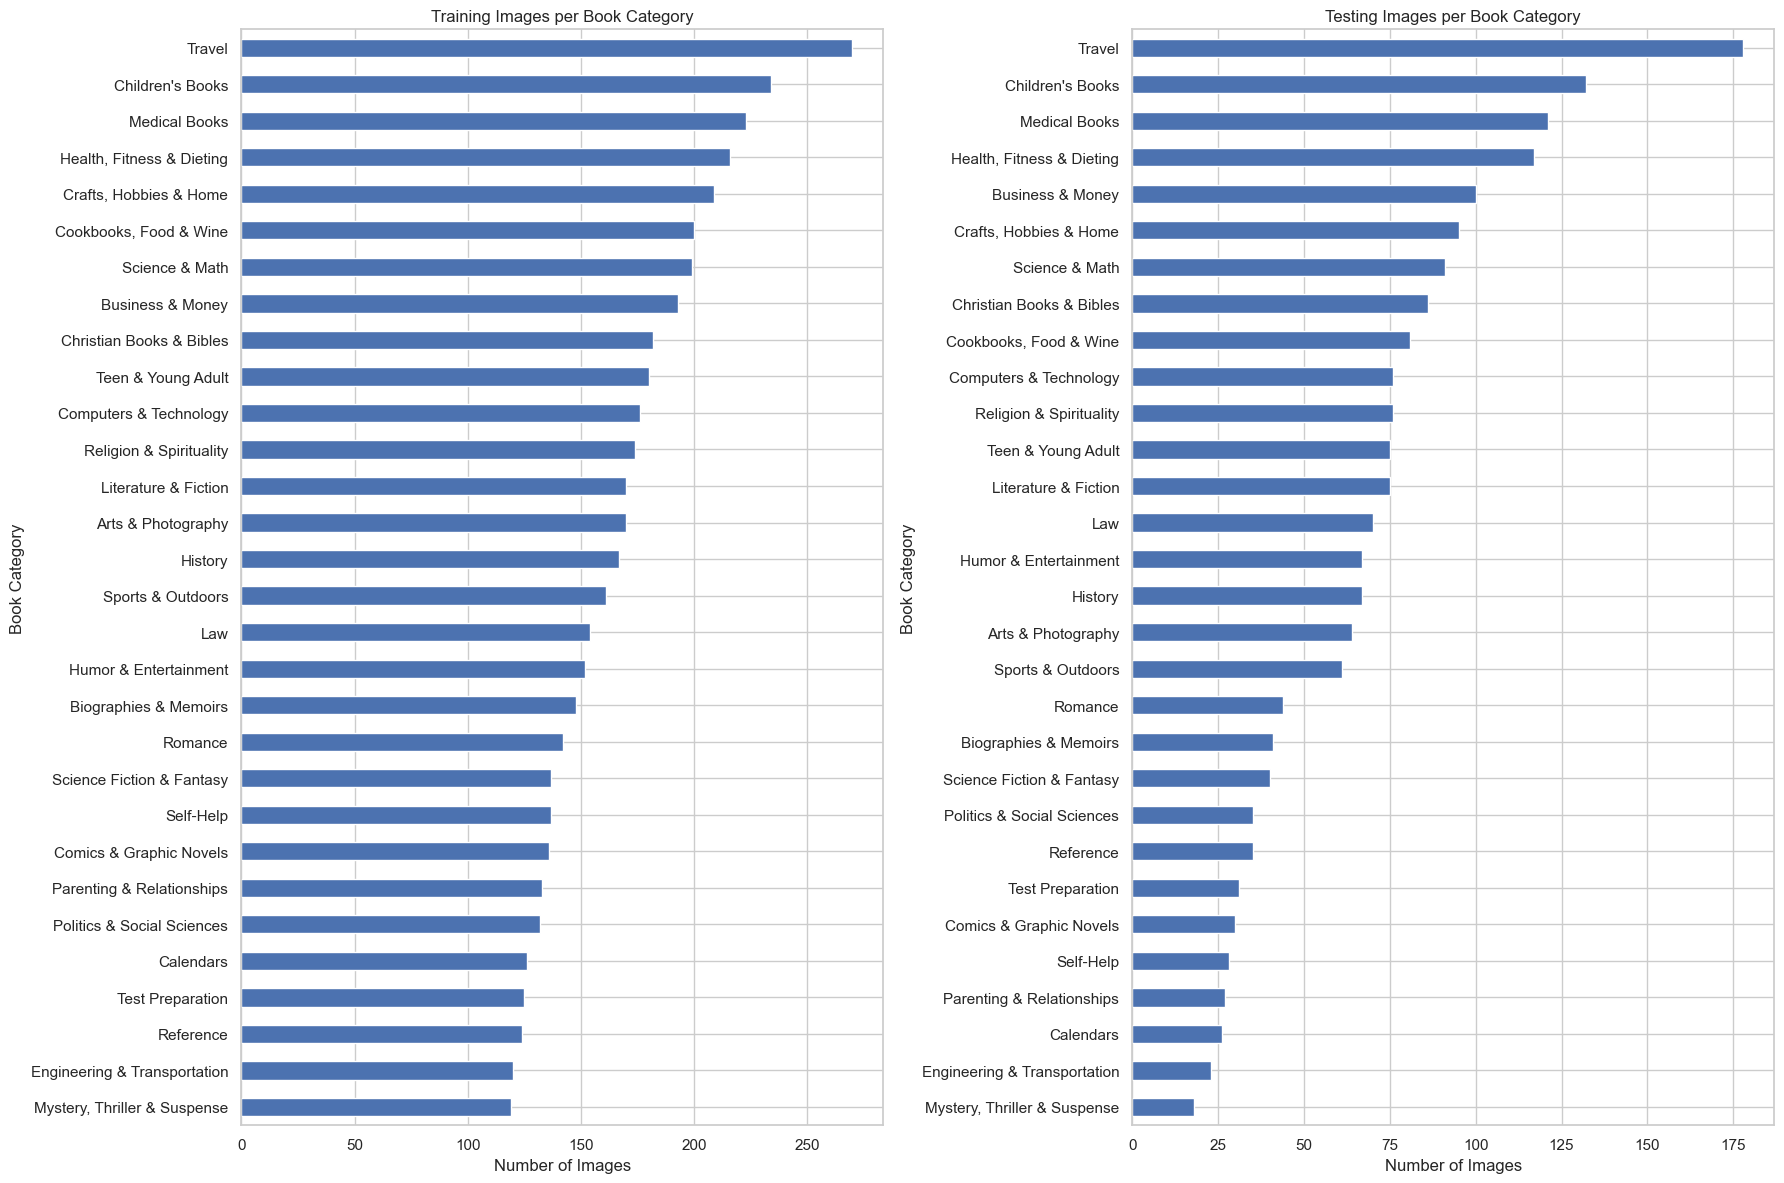

In [70]:
# Create two charts to compare category distributions
fig, axes = plt.subplots(1, 2, figsize=(18, 12))

# Training image distribution
category_distribution["Training Images"].sort_values().plot(
    kind="barh",
    ax=axes[0]
)

axes[0].set_title("Training Images per Book Category")
axes[0].set_xlabel("Number of Images")
axes[0].set_ylabel("Book Category")

# Testing image distribution
category_distribution["Testing Images"].sort_values().plot(
    kind="barh",
    ax=axes[1]
)

axes[1].set_title("Testing Images per Book Category")
axes[1].set_xlabel("Number of Images")
axes[1].set_ylabel("Book Category")

plt.tight_layout()
plt.show()

In [71]:
# Set the number of images per category
TRAIN_IMAGES_PER_CATEGORY = 100
TEST_IMAGES_PER_CATEGORY = 18

# Randomly select 100 training images from each category
train_sample_df = (
    train_available_df
    .groupby("category", group_keys=False)
    .sample(
        n=TRAIN_IMAGES_PER_CATEGORY,
        random_state=42
    )
    .reset_index(drop=True)
)

# Randomly select 18 testing images from each category
test_sample_df = (
    test_available_df
    .groupby("category", group_keys=False)
    .sample(
        n=TEST_IMAGES_PER_CATEGORY,
        random_state=42
    )
    .reset_index(drop=True)
)

# Display the dataset sizes
print("BALANCED DATASET SUMMARY")

print("\nTraining images:", len(train_sample_df))
print("Testing images:", len(test_sample_df))
print("Total images:", len(train_sample_df) + len(test_sample_df))

print("\nTraining categories:",
      train_sample_df["category"].nunique())

print("Testing categories:",
      test_sample_df["category"].nunique())

# Verify the number of images per category
print("\nTraining distribution:")
display(train_sample_df["category"].value_counts().sort_index())

print("\nTesting distribution:")
display(test_sample_df["category"].value_counts().sort_index())

BALANCED DATASET SUMMARY

Training images: 3000
Testing images: 540
Total images: 3540

Training categories: 30
Testing categories: 30

Training distribution:


category
Arts & Photography              100
Biographies & Memoirs           100
Business & Money                100
Calendars                       100
Children's Books                100
Christian Books & Bibles        100
Comics & Graphic Novels         100
Computers & Technology          100
Cookbooks, Food & Wine          100
Crafts, Hobbies & Home          100
Engineering & Transportation    100
Health, Fitness & Dieting       100
History                         100
Humor & Entertainment           100
Law                             100
Literature & Fiction            100
Medical Books                   100
Mystery, Thriller & Suspense    100
Parenting & Relationships       100
Politics & Social Sciences      100
Reference                       100
Religion & Spirituality         100
Romance                         100
Science & Math                  100
Science Fiction & Fantasy       100
Self-Help                       100
Sports & Outdoors               100
Teen & Young Adult 


Testing distribution:


category
Arts & Photography              18
Biographies & Memoirs           18
Business & Money                18
Calendars                       18
Children's Books                18
Christian Books & Bibles        18
Comics & Graphic Novels         18
Computers & Technology          18
Cookbooks, Food & Wine          18
Crafts, Hobbies & Home          18
Engineering & Transportation    18
Health, Fitness & Dieting       18
History                         18
Humor & Entertainment           18
Law                             18
Literature & Fiction            18
Medical Books                   18
Mystery, Thriller & Suspense    18
Parenting & Relationships       18
Politics & Social Sciences      18
Reference                       18
Religion & Spirituality         18
Romance                         18
Science & Math                  18
Science Fiction & Fantasy       18
Self-Help                       18
Sports & Outdoors               18
Teen & Young Adult              18
Test Prepar

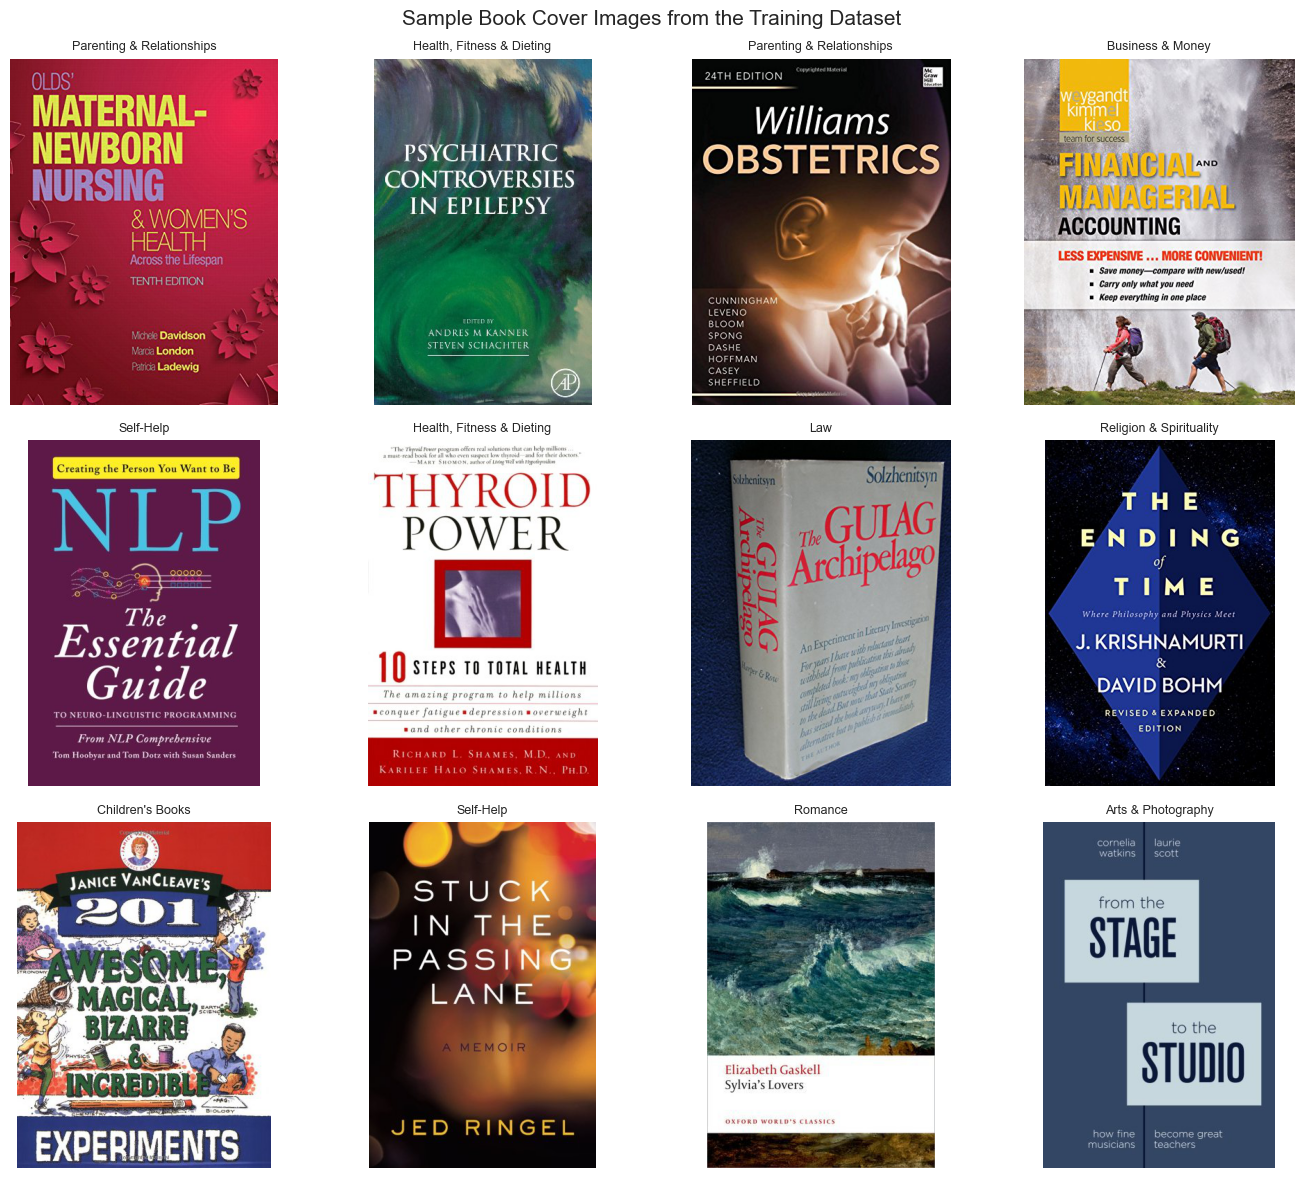

In [73]:
from PIL import Image

# Select 12 random training images
sample_images = train_sample_df.sample(
    n=12,
    random_state=42
).reset_index(drop=True)

# Create a visualisation grid
fig, axes = plt.subplots(3, 4, figsize=(14, 12))

for ax, (_, row) in zip(axes.flatten(), sample_images.iterrows()):

    image_path = os.path.join(
        train_image_folder,
        row["image_filename"]
    )

    # Open and display the book cover
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(row["category"], fontsize=9)
    ax.axis("off")

plt.suptitle("Sample Book Cover Images from the Training Dataset",
             fontsize=15)

plt.tight_layout()
plt.show()

In [74]:
from PIL import Image
import os
import pandas as pd

def inspect_images(dataframe, folder, dataset_name):

    image_information = []
    corrupted_images = []

    for _, row in dataframe.iterrows():

        image_path = os.path.join(
            folder,
            row["image_filename"]
        )

        try:
            with Image.open(image_path) as img:

                # Record image information
                image_information.append({
                    "filename": row["image_filename"],
                    "category": row["category"],
                    "width": img.width,
                    "height": img.height,
                    "format": img.format,
                    "mode": img.mode
                })

                # Verify that the image can be read
                img.verify()

        except Exception:
            corrupted_images.append(row["image_filename"])

    image_info_df = pd.DataFrame(image_information)

    print("\n", dataset_name, "IMAGE QUALITY REPORT")
    print("-----------------------------------")
    print("Total images checked:", len(dataframe))
    print("Valid images:", len(image_info_df))
    print("Corrupted or unreadable images:",
          len(corrupted_images))

    if len(image_info_df) > 0:

        print("\nImage dimension statistics:")
        display(
            image_info_df[["width", "height"]].describe()
        )

        print("\nImage formats:")
        display(image_info_df["format"].value_counts())

        print("\nImage colour modes:")
        display(image_info_df["mode"].value_counts())

        print("\nMost common image dimensions:")
        display(
            image_info_df.groupby(
                ["width", "height"]
            ).size().sort_values(
                ascending=False
            ).head(10)
        )

    return image_info_df, corrupted_images


# Inspect training images
train_image_info, train_corrupted = inspect_images(
    train_sample_df,
    train_image_folder,
    "TRAINING"
)

# Inspect testing images
test_image_info, test_corrupted = inspect_images(
    test_sample_df,
    test_image_folder,
    "TESTING"
)


 TRAINING IMAGE QUALITY REPORT
-----------------------------------
Total images checked: 3000
Valid images: 3000
Corrupted or unreadable images: 0

Image dimension statistics:


,width,height
count,3000.000000,3000.00000
mean,357.369667,490.87600
std,56.979996,41.93585
min,88.000000,123.00000
25%,329.000000,500.00000
50%,334.000000,500.00000
75%,389.000000,500.00000
max,713.000000,500.00000



Image formats:


format
JPEG    2987
GIF       13
Name: count, dtype: int64


Image colour modes:


mode
RGB    2987
P        13
Name: count, dtype: int64

... (6 outputs left out)


Image colour modes:


mode
RGB    539
P        1
Name: count, dtype: int64


Most common image dimensions:


width  height
333    500       76
324    500       29
500    500       24
328    500       15
334    500       13
329    500       13
325    500       11
313    500       10
332    500        9
330    500        9
dtype: int64

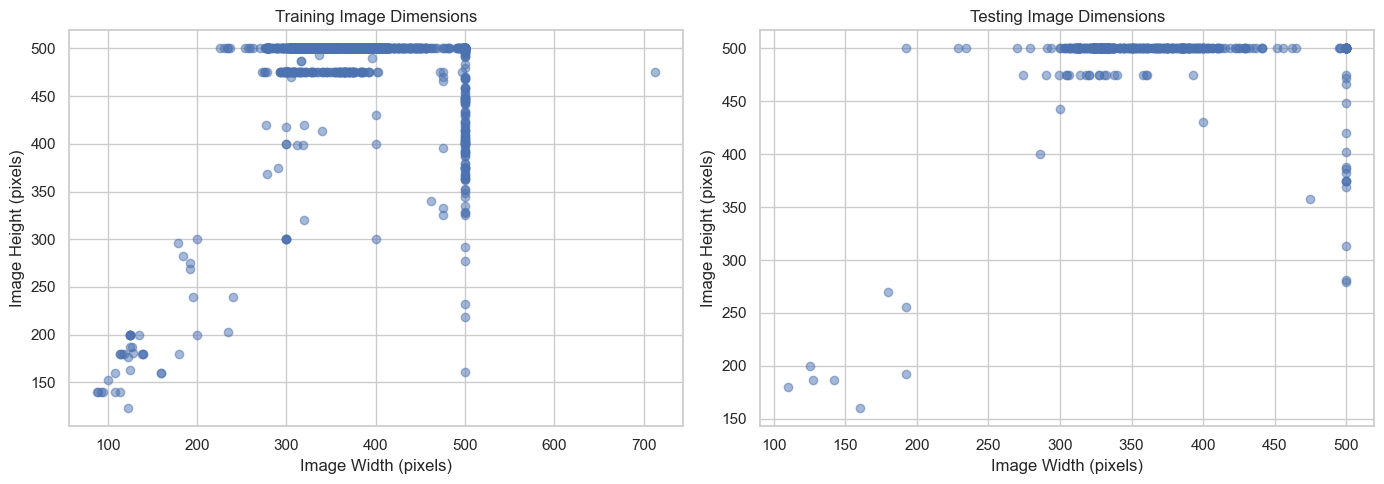

In [75]:
# Plot the distribution of image widths and heights
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training image dimensions
axes[0].scatter(
    train_image_info["width"],
    train_image_info["height"],
    alpha=0.5
)

axes[0].set_title("Training Image Dimensions")
axes[0].set_xlabel("Image Width (pixels)")
axes[0].set_ylabel("Image Height (pixels)")

# Testing image dimensions
axes[1].scatter(
    test_image_info["width"],
    test_image_info["height"],
    alpha=0.5
)

axes[1].set_title("Testing Image Dimensions")
axes[1].set_xlabel("Image Width (pixels)")
axes[1].set_ylabel("Image Height (pixels)")

plt.tight_layout()
plt.show()

In [76]:
import hashlib
import os

# Check for overlapping book identifiers
train_asins = set(train_sample_df["asin"])
test_asins = set(test_sample_df["asin"])

asin_overlap = train_asins.intersection(test_asins)

# Check for overlapping image filenames
train_filenames = set(train_sample_df["image_filename"])
test_filenames = set(test_sample_df["image_filename"])

filename_overlap = train_filenames.intersection(test_filenames)


# Function to calculate image file hashes
def calculate_image_hashes(dataframe, folder):

    image_hashes = {}

    for filename in dataframe["image_filename"]:

        image_path = os.path.join(folder, filename)

        with open(image_path, "rb") as image_file:
            file_hash = hashlib.sha256(
                image_file.read()
            ).hexdigest()

        image_hashes[filename] = file_hash

    return set(image_hashes.values())


# Calculate hashes for both datasets
train_hashes = calculate_image_hashes(
    train_sample_df,
    train_image_folder
)

test_hashes = calculate_image_hashes(
    test_sample_df,
    test_image_folder
)

# Identify identical image files
image_hash_overlap = train_hashes.intersection(test_hashes)


# Display results
print("DATA LEAKAGE CHECK")
print("--------------------------")

print("Overlapping ASIN identifiers:", len(asin_overlap))
print("Overlapping image filenames:", len(filename_overlap))
print("Identical image files:", len(image_hash_overlap))

if (
    len(asin_overlap) == 0
    and len(filename_overlap) == 0
    and len(image_hash_overlap) == 0
):
    print("\nNo overlap detected in the selected datasets.")
else:
    print("\nWARNING: Potential overlap detected.")

DATA LEAKAGE CHECK
--------------------------
Overlapping ASIN identifiers: 0
Overlapping image filenames: 0
Identical image files: 0

No overlap detected in the selected datasets.


In [77]:
# Import libraries for CNN development
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np
import os

# Display TensorFlow version
print("TensorFlow version:", tf.__version__)

# Check available processing devices
print("\nAvailable processing devices:")
print(tf.config.list_physical_devices())

# Check GPU availability
print("\nGPU available:",
      len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0

Available processing devices:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

GPU available: False


In [78]:
# Create a label encoder
label_encoder = LabelEncoder()

# Fit the encoder using the 30 book categories
label_encoder.fit(train_sample_df["category"])

# Convert training categories into numerical labels
train_sample_df["category_label"] = (
    label_encoder.transform(train_sample_df["category"])
)

# Convert testing categories using the same encoder
test_sample_df["category_label"] = (
    label_encoder.transform(test_sample_df["category"])
)

# Display the category-to-label mapping
category_mapping = pd.DataFrame({
    "Category": label_encoder.classes_,
    "Numerical Label": range(len(label_encoder.classes_))
})

print("NUMBER OF BOOK CATEGORIES:",
      len(label_encoder.classes_))

display(category_mapping)

NUMBER OF BOOK CATEGORIES: 30


,Category,Numerical Label
0,Arts & Photography,0
1,Biographies & Memoirs,1
2,Business & Money,2
3,Calendars,3
4,Children's Books,4
5,Christian Books & Bibles,5
6,Comics & Graphic Novels,6
7,Computers & Technology,7
8,"Cookbooks, Food & Wine",8
9,"Crafts, Hobbies & Home",9


In [79]:
# Separate training image filenames and labels
X = train_sample_df["image_filename"].values
y = train_sample_df["category_label"].values

# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the split results
print("TRAINING AND VALIDATION SPLIT")

print("\nTraining images:", len(X_train))
print("Validation images:", len(X_val))

print("\nTraining labels:", len(y_train))
print("Validation labels:", len(y_val))

print("\nNumber of training categories:",
      len(np.unique(y_train)))

print("Number of validation categories:",
      len(np.unique(y_val)))

TRAINING AND VALIDATION SPLIT

Training images: 2400
Validation images: 600

Training labels: 2400
Validation labels: 600

Number of training categories: 30
Number of validation categories: 30


In [80]:
from PIL import Image
import numpy as np
import os

In [81]:
# Define the image dimensions
IMG_HEIGHT = 180
IMG_WIDTH = 180

# Function to load and preprocess images
def load_images(filenames, image_folder):

    images = []

    for filename in filenames:

        image_path = os.path.join(
            image_folder,
            filename
        )

        # Open image and convert to RGB
        image = Image.open(image_path).convert("RGB")

        # Resize image
        image = image.resize(
            (IMG_WIDTH, IMG_HEIGHT)
        )

        # Convert image into a numerical array
        image_array = np.array(image)

        images.append(image_array)

    # Convert list into NumPy array
    images = np.array(images, dtype="float32")

    # Normalise pixel values between 0 and 1
    images = images / 255.0

    return images

In [82]:
# Load training images
X_train_images = load_images(
    X_train,
    train_image_folder
)

# Load validation images
X_val_images = load_images(
    X_val,
    train_image_folder
)

# Load testing images
X_test_images = load_images(
    test_sample_df["image_filename"].values,
    test_image_folder
)

# Extract testing labels
y_test = test_sample_df["category_label"].values

# Display dataset shapes
print("IMAGE PREPROCESSING RESULTS")

print("\nTraining images:", X_train_images.shape)
print("Validation images:", X_val_images.shape)
print("Testing images:", X_test_images.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

print("\nMinimum pixel value:", X_train_images.min())
print("Maximum pixel value:", X_train_images.max())

IMAGE PREPROCESSING RESULTS

Training images: (2400, 180, 180, 3)
Validation images: (600, 180, 180, 3)
Testing images: (540, 180, 180, 3)

Training labels: (2400,)
Validation labels: (600,)
Testing labels: (540,)

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [83]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [84]:
# Create the baseline CNN model
cnn_model = models.Sequential([

    # Input layer
    layers.Input(shape=(180, 180, 3)),

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Classification layer
    layers.Dense(128, activation="relu"),

    # Dropout to reduce overfitting
    layers.Dropout(0.5),

    # Output layer: 30 book categories
    layers.Dense(30, activation="softmax")
])

# Display the model architecture
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         3,870 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,650,846 (25.37 MB)

 Trainable params: 6,650,846 (25.37 MB)

 Non-trainable params: 0 (0.00 B)

In [85]:
cnn_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [86]:
# Define callbacks
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

# Train the CNN
history = cnn_model.fit(

    X_train_images,
    y_train,

    validation_data=(
        X_val_images,
        y_val
    ),

    epochs=20,

    batch_size=32,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - accuracy: 0.0267 - loss: 3.4573 - val_accuracy: 0.0350 - val_loss: 3.3970 - learning_rate: 0.0010
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 190s 2s/step - accuracy: 0.0417 - loss: 3.3860 - val_accuracy: 0.0617 - val_loss: 3.3891 - learning_rate: 0.0010
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 159s 2s/step - accuracy: 0.0729 - loss: 3.3238 - val_accuracy: 0.0583 - val_loss: 3.3900 - learning_rate: 0.0010
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 157s 2s/step - accuracy: 0.1317 - loss: 3.1472 - val_accuracy: 0.0617 - val_loss: 3.4321 - learning_rate: 0.0010
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 167s 2s/step - accuracy: 0.2558 - loss: 2.6732 - val_accuracy: 0.0850 - val_loss: 3.5679 - learning_rate: 5.0000e-04
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.3500 - loss: 2.3367 - val_accuracy: 0.0633 - val_loss: 3.8231 - learning_rate: 5.0000e-04


In [87]:
# Display the training history
training_results = pd.DataFrame(history.history)

display(training_results)

print("\nBest training accuracy:",
      round(max(history.history["accuracy"]) * 100, 2), "%")

print("Best validation accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.026667,3.457279,0.035000,3.396972,0.0010
1,0.041667,3.386025,0.061667,3.389101,0.0010
2,0.072917,3.323797,0.058333,3.389989,0.0010
3,0.131667,3.147209,0.061667,3.432079,0.0010
4,0.255833,2.673192,0.085000,3.567879,0.0005
5,0.350000,2.336725,0.063333,3.823099,0.0005



Best training accuracy: 35.0 %
Best validation accuracy: 8.5 %


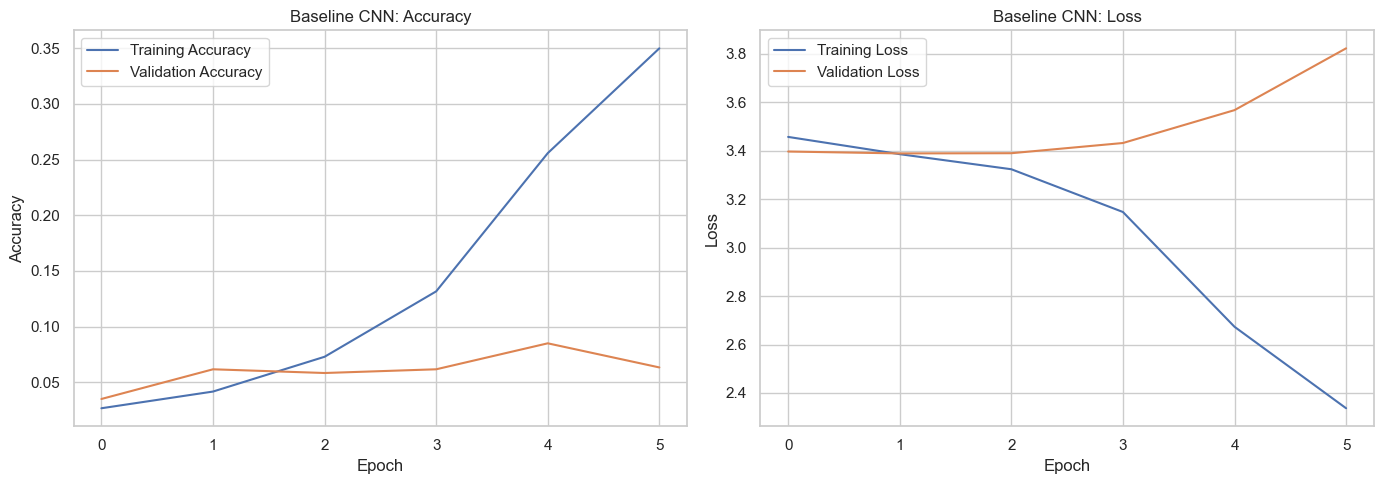

In [88]:
# Plot training and validation accuracy and loss

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("Baseline CNN: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss graph
axes[1].plot(
    history.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Baseline CNN: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [89]:
from tensorflow.keras import regularizers

# Build an improved CNN model
improved_cnn = models.Sequential([

    layers.Input(shape=(180, 180, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),

    # First convolutional block
    layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(
        64, (3, 3),
        padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(
        128, (3, 3),
        padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Fourth convolutional block
    layers.Conv2D(
        256, (3, 3),
        padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),

    # Reduce feature-map dimensions
    layers.GlobalAveragePooling2D(),

    # Classification layer with regularisation
    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.5),

    # Output layer for 30 categories
    layers.Dense(30, activation="softmax")
])

# Display architecture
improved_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 180, 180, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 22, 22, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 22, 22, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 30)             │         3,870 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 427,102 (1.63 MB)

 Trainable params: 426,142 (1.63 MB)

 Non-trainable params: 960 (3.75 KB)

In [90]:
improved_cnn.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Improved CNN compiled successfully!")

Improved CNN compiled successfully!


In [2]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [3]:
# Define callbacks for the improved CNN

improved_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

improved_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

print("Improved CNN callbacks defined successfully.")

Improved CNN callbacks defined successfully.


In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [6]:
improved_cnn = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),

    # First convolutional block
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Fourth convolutional block
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),

    # Classification layers
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.5),
    layers.Dense(30, activation="softmax")
])

print("Improved CNN model created successfully.")

Improved CNN model created successfully.


In [7]:
improved_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Improved CNN model compiled successfully.")

Improved CNN model compiled successfully.


In [8]:
improved_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

improved_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

print("Callbacks created successfully.")

Callbacks created successfully.


In [10]:
print("Training filenames:", "X_train" in globals())
print("Validation filenames:", "X_val" in globals())
print("Training labels:", "y_train" in globals())
print("Validation labels:", "y_val" in globals())
print("Training image folder:", "train_image_folder" in globals())
print("Image loading function:", "load_images" in globals())

Training filenames: False
Validation filenames: False
Training labels: False
Validation labels: False
Training image folder: False
Image loading function: False


In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Project directory
PROJECT_DIR = r"C:\Users\mosim\book30_project"

# CSV file locations
TRAIN_CSV = os.path.join(PROJECT_DIR, "book30-listing-train.csv")
TEST_CSV = os.path.join(PROJECT_DIR, "book30-listing-test.csv")

# Image folders
train_image_folder = os.path.join(PROJECT_DIR, "images", "train")
test_image_folder = os.path.join(PROJECT_DIR, "images", "test_book30")

# Check whether files and folders exist
print("Training CSV exists:", os.path.exists(TRAIN_CSV))
print("Testing CSV exists:", os.path.exists(TEST_CSV))
print("Training image folder exists:", os.path.exists(train_image_folder))
print("Testing image folder exists:", os.path.exists(test_image_folder))

Training CSV exists: False
Testing CSV exists: False
Training image folder exists: True
Testing image folder exists: True


In [12]:
import os

PROJECT_DIR = r"C:\Users\mosim\book30_project"

print("Files in project folder:")

for file in os.listdir(PROJECT_DIR):
    print(file)

Files in project folder:
images


In [13]:
print("\nCSV files found:")

for file in os.listdir(PROJECT_DIR):
    if file.lower().endswith(".csv"):
        print(file)


CSV files found:


In [14]:
import os

print("Current Jupyter working directory:")
print(os.getcwd())

print("\nFiles in the current directory:")

for file in os.listdir(os.getcwd()):
    print(file)

Current Jupyter working directory:
C:\Users\mosim

Files in the current directory:
.anaconda
.conda
.condarc
.continuum
.ipynb_checkpoints
.ipython
.jupyter
.keras
.matplotlib
.scala_history_jline3
.vscode
anaconda3
anaconda_projects
AppData
Application Data
archive.zip
ass2.ipynb
assignment2.ipynb
book30-listing-train.csv
book30_project
breast-cancer.csv
Contacts
Cookies
Desktop
Documents
Downloads
Epi Info 7
Favorites
insurance.csv
Links
Local Settings
Medical_Aid_Reviews_500.csv
MM_MALEFO_ST10533164_ICE_TASK2.ipynb
MM_MALEFO_ST10533164_PART2_PDA.ipynb
mosima.ipynb
Music
My Documents
NetHood
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{05a6bc23-9ccf-11f0-af43-ad75c7a32c8a}.TM.blf
NTUSER.DAT{05a6bc23-9ccf-11f0-af43-ad75c7a32c8a}.TMContainer00000000000000000001.regtrans-ms
NTUSER.DAT{05a6bc23-9ccf-11f0-af43-ad75c7a32c8a}.TMContainer00000000000000000002.regtrans-ms
ntuser.ini
OneDrive
Pictures
POE FINAL.ipynb
POE.ipynb
POE21.ipynb
PrintHood
Recent
Saved Games
Searches
SendTo
ST

In [15]:
downloads_folder = os.path.expanduser("~/Downloads")

print("CSV files in Downloads:")

for file in os.listdir(downloads_folder):
    if file.lower().endswith(".csv"):
        print(file)

CSV files in Downloads:
book30-listing-test.csv
book30-listing-train.csv
breast-cancer - Copy.csv
breast-cancer.csv
Medical_Aid_Reviews_500 - Copy.csv
Medical_Aid_Reviews_500.csv
train.csv
Walmart_Sales.csv


In [17]:
import os
import pandas as pd
import numpy as np

# Locate CSV files in Downloads
downloads_folder = os.path.expanduser("~/Downloads")

TRAIN_CSV = os.path.join(downloads_folder, "book30-listing-train.csv")
TEST_CSV = os.path.join(downloads_folder, "book30-listing-test.csv")

# Load CSV files using Latin-1 encoding
train_df = pd.read_csv(TRAIN_CSV, encoding="latin1")
test_df = pd.read_csv(TEST_CSV, encoding="latin1")

# Display dataset information
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

Training dataset shape: (51299, 7)
Testing dataset shape: (5699, 7)

Training columns:
['1588345297', '1588345297.jpg', 'http://ecx.images-amazon.com/images/I/51l6XIoa3rL.jpg', 'With Schwarzkopf: Life Lessons of The Bear', 'Gus Lee', '1', 'Biographies & Memoirs']

Testing columns:
['044310073X', '044310073X.jpg', 'http://ecx.images-amazon.com/images/I/41kSLEoswsL.jpg', 'Oral and Maxillofacial Surgery: An Objective-Based Textbook, 2e', 'Unnamed: 4', '16', 'Medical Books']


In [18]:
import os
import pandas as pd
import numpy as np

# Dataset location
downloads_folder = os.path.expanduser("~/Downloads")

TRAIN_CSV = os.path.join(downloads_folder, "book30-listing-train.csv")
TEST_CSV = os.path.join(downloads_folder, "book30-listing-test.csv")

# Define the correct column names
column_names = [
    "asin",
    "image_filename",
    "image_url",
    "title",
    "author",
    "category_id",
    "category"
]

# Load datasets without treating the first row as headers
train_df = pd.read_csv(
    TRAIN_CSV,
    encoding="latin1",
    header=None,
    names=column_names
)

test_df = pd.read_csv(
    TEST_CSV,
    encoding="latin1",
    header=None,
    names=column_names
)

# Replace missing authors
train_df["author"] = train_df["author"].fillna("Unknown")
test_df["author"] = test_df["author"].fillna("Unknown")

# Display results
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nTraining dataset:")
display(train_df.head())

print("\nTesting dataset:")
display(test_df.head())

Training dataset shape: (51300, 7)
Testing dataset shape: (5700, 7)

Training dataset:


,asin,image_filename,image_url,title,author,category_id,category
0,1588345297,1588345297.jpg,http://ecx.images-amazon.com/images/I/51l6XIoa...,With Schwarzkopf: Life Lessons of The Bear,Gus Lee,1,Biographies & Memoirs
1,1404803335,1404803335.jpg,http://ecx.images-amazon.com/images/I/51UJnL3T...,"Magnets: Pulling Together, Pushing Apart (Amaz...",Natalie M. Rosinsky,4,Children's Books
2,1446276082,1446276082.jpg,http://ecx.images-amazon.com/images/I/51MGUKhk...,Energy Security (SAGE Library of International...,Unknown,10,Engineering & Transportation
3,1491522666,1491522666.jpg,http://ecx.images-amazon.com/images/I/51qKvjsi...,An Amish Gathering: Life in Lancaster County,Beth Wiseman,9,Christian Books & Bibles
4,970096410,0970096410.jpg,http://ecx.images-amazon.com/images/I/51qoUENb...,City of Rocks Idaho: A Climber's Guide (Region...,Dave Bingham,26,Sports & Outdoors



Testing dataset:


,asin,image_filename,image_url,title,author,category_id,category
0,044310073X,044310073X.jpg,http://ecx.images-amazon.com/images/I/41kSLEos...,Oral and Maxillofacial Surgery: An Objective-B...,Unknown,16,Medical Books
1,1438005687,1438005687.jpg,http://ecx.images-amazon.com/images/I/510l0qhi...,"Barron's GRE, 21st Edition",Sharon Weiner Green M.A.,28,Test Preparation
2,60750715,0060750715.jpg,http://ecx.images-amazon.com/images/I/51p5aUY%...,George Balanchine: The Ballet Maker (Eminent L...,Robert Gottlieb,1,Biographies & Memoirs
3,1580237959,1580237959.jpg,http://ecx.images-amazon.com/images/I/51pum0eW...,"A Partner in Holiness: Deepening Mindfulness, ...",Rabbi Jonathan P. Slater DMin,21,Religion & Spirituality
4,135137829,0135137829.jpg,http://ecx.images-amazon.com/images/I/51PuTPPC...,Construction Scheduling: Principles and Practi...,Jay S. Newitt,0,Arts & Photography


In [19]:
print("Training categories:", train_df["category"].nunique())
print("Testing categories:", test_df["category"].nunique())

print("\nTraining records per category:")
print(train_df["category"].value_counts().sort_index().head(10))

Training categories: 30
Testing categories: 30

Training records per category:
category
Arts & Photography          1710
Biographies & Memoirs       1710
Business & Money            1710
Calendars                   1710
Children's Books            1710
Christian Books & Bibles    1710
Comics & Graphic Novels     1710
Computers & Technology      1710
Cookbooks, Food & Wine      1710
Crafts, Hobbies & Home      1710
Name: count, dtype: int64


In [20]:
import os

# Image folder paths
train_image_folder = r"C:\Users\mosim\book30_project\images\train"
test_image_folder = r"C:\Users\mosim\book30_project\images\test_book30"

# Get image filenames from folders
available_train_images = set(os.listdir(train_image_folder))
available_test_images = set(os.listdir(test_image_folder))

print("Available training images:", len(available_train_images))
print("Available testing images:", len(available_test_images))

Available training images: 5009
Available testing images: 2010


In [21]:
# Keep only records whose images exist in the folders
train_available_df = train_df[
    train_df["image_filename"].isin(available_train_images)
].copy()

test_available_df = test_df[
    test_df["image_filename"].isin(available_test_images)
].copy()

print("Available training records:", len(train_available_df))
print("Available testing records:", len(test_available_df))

print("\nTraining records per category:")
print(train_available_df["category"].value_counts().sort_index())

print("\nTesting records per category:")
print(test_available_df["category"].value_counts().sort_index())

Available training records: 5009
Available testing records: 2010

Training records per category:
category
Arts & Photography              170
Biographies & Memoirs           148
Business & Money                193
Calendars                       126
Children's Books                234
Christian Books & Bibles        182
Comics & Graphic Novels         136
Computers & Technology          176
Cookbooks, Food & Wine          200
Crafts, Hobbies & Home          209
Engineering & Transportation    120
Health, Fitness & Dieting       216
History                         167
Humor & Entertainment           152
Law                             154
Literature & Fiction            170
Medical Books                   223
Mystery, Thriller & Suspense    119
Parenting & Relationships       133
Politics & Social Sciences      132
Reference                       124
Religion & Spirituality         174
Romance                         142
Science & Math                  199
Science Fiction & Fantasy     

In [22]:
# Select 100 training images per category
train_sample_df = (
    train_available_df
    .groupby("category", group_keys=False)
    .sample(n=100, random_state=42)
    .reset_index(drop=True)
)

# Select 18 testing images per category
test_sample_df = (
    test_available_df
    .groupby("category", group_keys=False)
    .sample(n=18, random_state=42)
    .reset_index(drop=True)
)

# Display dataset sizes
print("Balanced training dataset:", train_sample_df.shape)
print("Balanced testing dataset:", test_sample_df.shape)

print("\nTraining images per category:")
print(train_sample_df["category"].value_counts().sort_index())

print("\nTesting images per category:")
print(test_sample_df["category"].value_counts().sort_index())

Balanced training dataset: (3000, 7)
Balanced testing dataset: (540, 7)

Training images per category:
category
Arts & Photography              100
Biographies & Memoirs           100
Business & Money                100
Calendars                       100
Children's Books                100
Christian Books & Bibles        100
Comics & Graphic Novels         100
Computers & Technology          100
Cookbooks, Food & Wine          100
Crafts, Hobbies & Home          100
Engineering & Transportation    100
Health, Fitness & Dieting       100
History                         100
Humor & Entertainment           100
Law                             100
Literature & Fiction            100
Medical Books                   100
Mystery, Thriller & Suspense    100
Parenting & Relationships       100
Politics & Social Sciences      100
Reference                       100
Religion & Spirituality         100
Romance                         100
Science & Math                  100
Science Fiction & Fantas

In [23]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

# Fit encoder on training categories
label_encoder.fit(train_sample_df["category"])

# Transform categories into numerical labels
train_sample_df["category_label"] = label_encoder.transform(
    train_sample_df["category"]
)

test_sample_df["category_label"] = label_encoder.transform(
    test_sample_df["category"]
)

print("Number of categories:", len(label_encoder.classes_))
print("Category labels restored successfully.")

display(pd.DataFrame({
    "Category": label_encoder.classes_,
    "Numerical Label": range(len(label_encoder.classes_))
}))

Number of categories: 30
Category labels restored successfully.


,Category,Numerical Label
0,Arts & Photography,0
1,Biographies & Memoirs,1
2,Business & Money,2
3,Calendars,3
4,Children's Books,4
5,Christian Books & Bibles,5
6,Comics & Graphic Novels,6
7,Computers & Technology,7
8,"Cookbooks, Food & Wine",8
9,"Crafts, Hobbies & Home",9


In [24]:
from sklearn.model_selection import train_test_split

X = train_sample_df["image_filename"].values
y = train_sample_df["category_label"].values

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Testing labels
y_test = test_sample_df["category_label"].values

print("Training filenames:", X_train.shape)
print("Validation filenames:", X_val.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

Training filenames: (2400,)
Validation filenames: (600,)
Training labels: (2400,)
Validation labels: (600,)
Testing labels: (540,)


In [25]:
import os
import numpy as np
from PIL import Image

# Image dimensions
IMG_HEIGHT = 180
IMG_WIDTH = 180

# Function to load and preprocess images
def load_images(filenames, image_folder):

    images = []

    for filename in filenames:

        image_path = os.path.join(image_folder, filename)

        image = Image.open(image_path).convert("RGB")

        image = image.resize((IMG_WIDTH, IMG_HEIGHT))

        image_array = np.array(image)

        images.append(image_array)

    images = np.array(images, dtype="float32")

    # Normalize pixel values
    images = images / 255.0

    return images

print("Image loading function restored successfully.")

Image loading function restored successfully.


In [26]:
# Load training images
X_train_images = load_images(
    X_train,
    train_image_folder
)

# Load validation images
X_val_images = load_images(
    X_val,
    train_image_folder
)

# Load testing images
X_test_images = load_images(
    test_sample_df["image_filename"].values,
    test_image_folder
)

print("Training images:", X_train_images.shape)
print("Validation images:", X_val_images.shape)
print("Testing images:", X_test_images.shape)

Training images: (2400, 180, 180, 3)
Validation images: (600, 180, 180, 3)
Testing images: (540, 180, 180, 3)


In [27]:
print("Training pixel minimum:", X_train_images.min())
print("Training pixel maximum:", X_train_images.max())

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

Training pixel minimum: 0.0
Training pixel maximum: 1.0
Training labels: (2400,)
Validation labels: (600,)
Testing labels: (540,)


In [28]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Create improved CNN model
improved_cnn = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),

    # First convolutional block
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Fourth convolutional block
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),

    # Feature extraction and classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.5),
    layers.Dense(30, activation="softmax")
])

print("Improved CNN model created successfully.")

Improved CNN model created successfully.


In [29]:
improved_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Improved CNN compiled successfully.")

Improved CNN compiled successfully.


In [30]:
improved_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

improved_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

print("Improved CNN callbacks created successfully.")

Improved CNN callbacks created successfully.


In [31]:
improved_history = improved_cnn.fit(
    X_train_images,
    y_train,
    validation_data=(X_val_images, y_val),
    epochs=10,
    batch_size=32,
    callbacks=[
        improved_early_stopping,
        improved_reduce_lr
    ],
    verbose=1
)

Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 231s 3s/step - accuracy: 0.0471 - loss: 3.6896 - val_accuracy: 0.0317 - val_loss: 3.5919 - learning_rate: 3.0000e-04
Epoch 2/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 203s 3s/step - accuracy: 0.0621 - loss: 3.5768 - val_accuracy: 0.0367 - val_loss: 3.6608 - learning_rate: 3.0000e-04
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 255s 3s/step - accuracy: 0.0692 - loss: 3.5129 - val_accuracy: 0.0300 - val_loss: 3.7218 - learning_rate: 3.0000e-04
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 206s 3s/step - accuracy: 0.0850 - loss: 3.4525 - val_accuracy: 0.0533 - val_loss: 3.6732 - learning_rate: 1.5000e-04
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 198s 3s/step - accuracy: 0.0925 - loss: 3.4105 - val_accuracy: 0.0550 - val_loss: 3.5927 - learning_rate: 1.5000e-04
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 207s 3s/step - accuracy: 0.0900 - loss: 3.3831 - val_accuracy: 0.0650 - val_loss: 3.5076 - learning_rate: 7.5000e-05
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 203s 3s/step - accuracy: 0.1242 

In [32]:
improved_results = pd.DataFrame(improved_history.history)

display(improved_results)

print(
    "Best training accuracy:",
    round(max(improved_history.history["accuracy"]) * 100, 2),
    "%"
)

print(
    "Best validation accuracy:",
    round(max(improved_history.history["val_accuracy"]) * 100, 2),
    "%"
)

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.047083,3.689573,0.031667,3.591884,0.000300
1,0.062083,3.576786,0.036667,3.660822,0.000300
2,0.069167,3.512906,0.030000,3.721765,0.000300
3,0.085000,3.452537,0.053333,3.673199,0.000150
4,0.092500,3.410511,0.055000,3.592745,0.000150
5,0.090000,3.383070,0.065000,3.507608,0.000075
6,0.124167,3.350845,0.078333,3.456465,0.000075
7,0.105417,3.353822,0.108333,3.430761,0.000075
8,0.115000,3.320919,0.105000,3.424898,0.000075
9,0.112917,3.311331,0.085000,3.417721,0.000075


Best training accuracy: 12.42 %
Best validation accuracy: 10.83 %


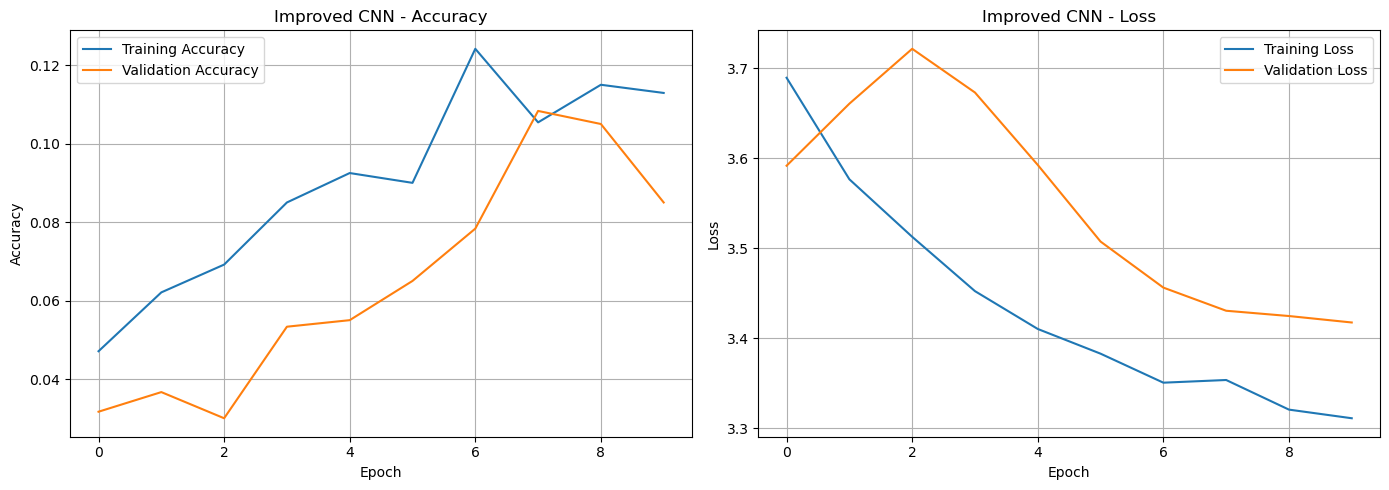

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(
    improved_history.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    improved_history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Improved CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(
    improved_history.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    improved_history.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Improved CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

# Predict the categories of the test images
y_pred_prob = improved_cnn.predict(X_test_images)

# Convert predicted probabilities into category labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

test_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

test_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("IMPROVED CNN TEST RESULTS")
print("-------------------------")
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Precision:", round(test_precision * 100, 2), "%")
print("Test Recall:", round(test_recall * 100, 2), "%")
print("Test F1-score:", round(test_f1 * 100, 2), "%")

17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 458ms/step
IMPROVED CNN TEST RESULTS
-------------------------
Test Accuracy: 8.89 %
Test Precision: 7.95 %
Test Recall: 8.89 %
Test F1-score: 7.27 %


In [35]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(30),
    target_names=label_encoder.classes_,
    zero_division=0
)

print("IMPROVED CNN CLASSIFICATION REPORT")
print("----------------------------------")
print(report)

IMPROVED CNN CLASSIFICATION REPORT
----------------------------------
                              precision    recall  f1-score   support

          Arts & Photography       0.00      0.00      0.00        18
       Biographies & Memoirs       0.17      0.11      0.13        18
            Business & Money       0.00      0.00      0.00        18
                   Calendars       0.10      0.06      0.07        18
            Children's Books       0.14      0.06      0.08        18
    Christian Books & Bibles       0.07      0.06      0.06        18
     Comics & Graphic Novels       0.09      0.11      0.10        18
      Computers & Technology       0.11      0.11      0.11        18
      Cookbooks, Food & Wine       0.08      0.06      0.06        18
      Crafts, Hobbies & Home       0.08      0.06      0.07        18
Engineering & Transportation       0.00      0.00      0.00        18
   Health, Fitness & Dieting       0.00      0.00      0.00        18
                   

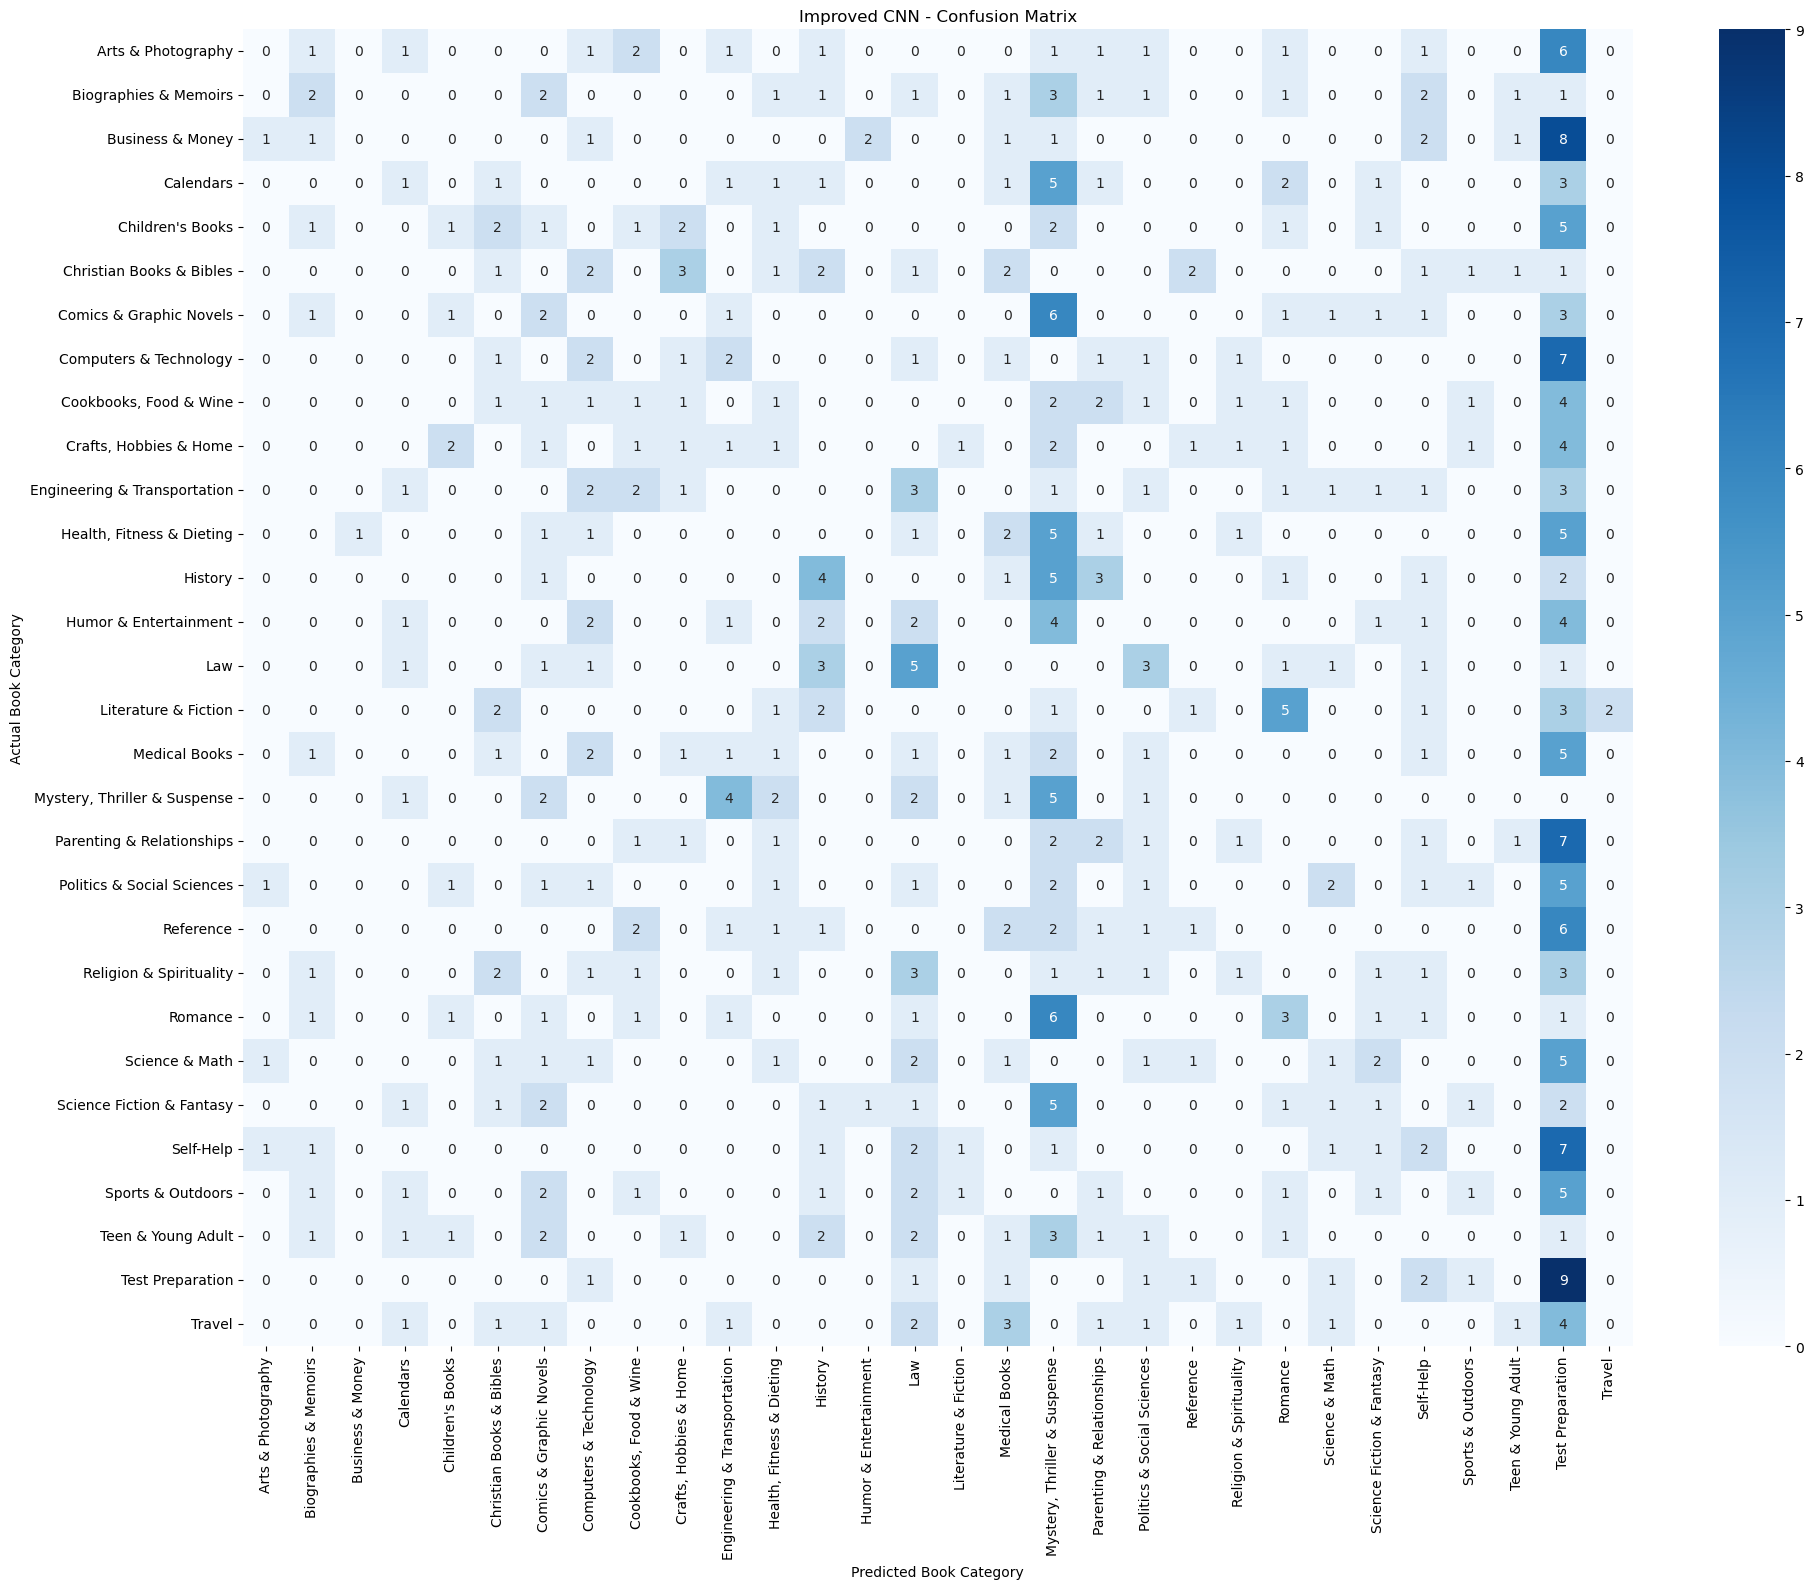

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(30)
)

# Plot confusion matrix
plt.figure(figsize=(20, 16))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Improved CNN - Confusion Matrix")
plt.xlabel("Predicted Book Category")
plt.ylabel("Actual Book Category")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [37]:
import numpy as np
import pandas as pd

# Get the number of correct predictions for each category
correct_predictions = np.diag(cm)

# Create a summary table
confusion_summary = pd.DataFrame({
    "Book Category": label_encoder.classes_,
    "Correct Predictions": correct_predictions,
    "Incorrect Predictions": 18 - correct_predictions
})

display(
    confusion_summary.sort_values(
        by="Correct Predictions",
        ascending=False
    )
)

,Book Category,Correct Predictions,Incorrect Predictions
28,Test Preparation,9,9
14,Law,5,13
17,"Mystery, Thriller & Suspense",5,13
12,History,4,14
22,Romance,3,15
6,Comics & Graphic Novels,2,16
7,Computers & Technology,2,16
18,Parenting & Relationships,2,16
1,Biographies & Memoirs,2,16
25,Self-Help,2,16


In [38]:
print("TRAINING DATA")
print("Training dataframe:", "train_available_df" in globals())
print("Training images:", "X_train_images" in globals())

print("\nVALIDATION DATA")
print("Validation images:", "X_val_images" in globals())

print("\nTEST DATA")
print("Test images:", "X_test_images" in globals())

print("\nLABEL ENCODER")
print("Label encoder:", "label_encoder" in globals())

print("\nIMAGE FOLDER")
print("Training image folder:", "train_image_folder" in globals())

print("\nTENSORFLOW")
print("TensorFlow version:", tf.__version__)

TRAINING DATA
Training dataframe: True
Training images: True

VALIDATION DATA
Validation images: True

TEST DATA
Test images: True

LABEL ENCODER
Label encoder: True

IMAGE FOLDER
Training image folder: True

TENSORFLOW
TensorFlow version: 2.21.0


In [39]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import os

# Copy all available training images
full_train_df = train_available_df.copy()

# Encode the 30 book categories
full_train_df["category_label"] = label_encoder.transform(
    full_train_df["category"]
)

# Get image file paths
image_paths = np.array([
    os.path.join(train_image_folder, filename)
    for filename in full_train_df["image_filename"]
])

# Get category labels
image_labels = full_train_df["category_label"].values

# Split into training and validation datasets
X_train_paths, X_val_paths, y_train_full, y_val_full = train_test_split(
    image_paths,
    image_labels,
    test_size=0.20,
    random_state=42,
    stratify=image_labels
)

# Prepare the existing separate test sample
test_mobilenet_df = test_sample_df.copy()

test_mobilenet_df["category_label"] = label_encoder.transform(
    test_mobilenet_df["category"]
)

X_test_paths = np.array([
    os.path.join(test_image_folder, filename)
    for filename in test_mobilenet_df["image_filename"]
])

y_test_full = test_mobilenet_df["category_label"].values

# Display dataset sizes
print("MOBILENETV2 DATASET SUMMARY")
print("---------------------------")
print("Total available training images:", len(full_train_df))
print("Training images:", len(X_train_paths))
print("Validation images:", len(X_val_paths))
print("Testing images:", len(X_test_paths))
print("Number of categories:", len(label_encoder.classes_))

MOBILENETV2 DATASET SUMMARY
---------------------------
Total available training images: 5009
Training images: 4007
Validation images: 1002
Testing images: 540
Number of categories: 30


In [40]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2,
    preprocess_input
)

IMG_SIZE = 160
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow version: 2.21.0
Image size: 160
Batch size: 32


In [41]:
def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = preprocess_input(image)

    return image, label

In [42]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_paths, y_train_full)
)

train_dataset = (
    train_dataset
    .shuffle(2000, seed=42)
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_paths, y_val_full)
)

val_dataset = (
    val_dataset
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_paths, y_test_full)
)

test_dataset = (
    test_dataset
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training, validation and testing datasets created successfully.")

Training, validation and testing datasets created successfully.


In [43]:
for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 160, 160, 3)
Label batch shape: (32,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


In [44]:
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import MobileNetV2

# Load MobileNetV2 with pre-trained ImageNet weights
base_model = MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pre-trained layers
base_model.trainable = False

# Build the complete classification model
mobilenet_model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.4),

    layers.Dense(30, activation="softmax")
])

print("MobileNetV2 model created successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
MobileNetV2 model created successfully!


In [45]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 model compiled successfully!")

MobileNetV2 model compiled successfully!


In [46]:
mobilenet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 30)             │         7,710 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593,630 (9.89 MB)

 Trainable params: 335,646 (1.28 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [47]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

mobilenet_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

mobilenet_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.000001,
    verbose=1
)

print("MobileNetV2 callbacks created successfully!")


MobileNetV2 callbacks created successfully!


In [48]:
mobilenet_history = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=[
        mobilenet_early_stopping,
        mobilenet_reduce_lr
    ],
    verbose=1
)

Epoch 1/10


C:\Users\mosim\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


126/126 ━━━━━━━━━━━━━━━━━━━━ 84s 595ms/step - accuracy: 0.0502 - loss: 4.0370 - val_accuracy: 0.0689 - val_loss: 3.7356 - learning_rate: 1.0000e-04
Epoch 2/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 114s 908ms/step - accuracy: 0.0996 - loss: 3.6960 - val_accuracy: 0.1208 - val_loss: 3.6357 - learning_rate: 1.0000e-04
Epoch 3/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 102s 586ms/step - accuracy: 0.1405 - loss: 3.5315 - val_accuracy: 0.1357 - val_loss: 3.5579 - learning_rate: 1.0000e-04
Epoch 4/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 82s 583ms/step - accuracy: 0.1650 - loss: 3.4093 - val_accuracy: 0.1507 - val_loss: 3.4969 - learning_rate: 1.0000e-04
Epoch 5/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 78s 621ms/step - accuracy: 0.1914 - loss: 3.2939 - val_accuracy: 0.1667 - val_loss: 3.4388 - learning_rate: 1.0000e-04
Epoch 6/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 81s 647ms/step - accuracy: 0.2321 - loss: 3.1853 - val_accuracy: 0.1657 - val_loss: 3.4009 - learning_rate: 1.0000e-04
Epoch 7/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 85s 674ms/step 

In [49]:
mobilenet_results = pd.DataFrame(
    mobilenet_history.history
)

display(mobilenet_results)

print(
    "Best training accuracy:",
    round(
        max(mobilenet_history.history["accuracy"]) * 100, 2
    ),
    "%"
)

print(
    "Best validation accuracy:",
    round(
        max(mobilenet_history.history["val_accuracy"]) * 100, 2
    ),
    "%"
)

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.050162,4.037024,0.068862,3.735621,0.0001
1,0.099576,3.696001,0.120758,3.635707,0.0001
2,0.140504,3.531478,0.135729,3.557873,0.0001
3,0.164961,3.409252,0.150699,3.496949,0.0001
4,0.191415,3.293869,0.166667,3.438768,0.0001
5,0.232094,3.185276,0.165669,3.400937,0.0001
6,0.258298,3.078443,0.186627,3.379125,0.0001
7,0.272024,2.997117,0.185629,3.353111,0.0001
8,0.301472,2.900285,0.174651,3.340898,0.0001
9,0.325930,2.809315,0.184631,3.322719,0.0001


Best training accuracy: 32.59 %
Best validation accuracy: 18.66 %


In [50]:
# Unfreeze the MobileNetV2 base model
base_model.trainable = True

# Freeze all layers except the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalisation layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile using a very low learning rate
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 fine-tuning configuration completed!")
print("Trainable parameters:", mobilenet_model.trainable_variables.__len__())

MobileNetV2 fine-tuning configuration completed!
Trainable parameters: 14


In [51]:
mobilenet_model.save("book30_mobilenetv2_before_finetuning.keras")

print("Original MobileNetV2 model saved successfully!")

Original MobileNetV2 model saved successfully!


In [52]:
mobilenet_finetune_history = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=1,
            min_lr=0.000001,
            verbose=1
        )
    ],
    verbose=1
)

Epoch 1/5


C:\Users\mosim\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


126/126 ━━━━━━━━━━━━━━━━━━━━ 97s 693ms/step - accuracy: 0.3484 - loss: 2.7044 - val_accuracy: 0.1856 - val_loss: 3.3289 - learning_rate: 1.0000e-05
Epoch 2/5
126/126 ━━━━━━━━━━━━━━━━━━━━ 87s 691ms/step - accuracy: 0.3704 - loss: 2.6112 - val_accuracy: 0.1956 - val_loss: 3.3123 - learning_rate: 1.0000e-05
Epoch 3/5
126/126 ━━━━━━━━━━━━━━━━━━━━ 91s 720ms/step - accuracy: 0.3873 - loss: 2.5310 - val_accuracy: 0.1936 - val_loss: 3.3091 - learning_rate: 1.0000e-05
Epoch 4/5
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 607ms/step - accuracy: 0.4068 - loss: 2.4821
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
126/126 ━━━━━━━━━━━━━━━━━━━━ 92s 725ms/step - accuracy: 0.4068 - loss: 2.4821 - val_accuracy: 0.2066 - val_loss: 3.3170 - learning_rate: 1.0000e-05
Epoch 5/5
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.4337 - loss: 2.3863
Epoch 5: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
126/126 ━━━━━━━━━━━━━━━━━━━━ 142s 725ms/step - accuracy: 0.433

In [53]:
mobilenet_test_loss, mobilenet_test_accuracy = (
    mobilenet_model.evaluate(test_dataset, verbose=1)
)

print("MobileNetV2 Test Loss:", round(mobilenet_test_loss, 4))

print(
    "MobileNetV2 Test Accuracy:",
    round(mobilenet_test_accuracy * 100, 2),
    "%"
)

17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 424ms/step - accuracy: 0.1537 - loss: 3.5068
MobileNetV2 Test Loss: 3.5068
MobileNetV2 Test Accuracy: 15.37 %


In [54]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Generate predictions
y_pred_prob_mobilenet = mobilenet_model.predict(test_dataset)

# Convert probabilities into predicted category labels
y_pred_mobilenet = np.argmax(y_pred_prob_mobilenet, axis=1)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test_full, y_pred_mobilenet) * 100, 2), "%")

print("Macro Precision:", round(
    precision_score(y_test_full, y_pred_mobilenet, average="macro", zero_division=0) * 100, 2
), "%")

print("Macro Recall:", round(
    recall_score(y_test_full, y_pred_mobilenet, average="macro", zero_division=0) * 100, 2
), "%")

print("Macro F1-score:", round(
    f1_score(y_test_full, y_pred_mobilenet, average="macro", zero_division=0) * 100, 2
), "%")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test_full,
    y_pred_mobilenet,
    labels=np.arange(30),
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
mobilenet_cm = confusion_matrix(
    y_test_full,
    y_pred_mobilenet,
    labels=np.arange(30)
)

print("Confusion matrix shape:", mobilenet_cm.shape)

17/17 ━━━━━━━━━━━━━━━━━━━━ 12s 541ms/step
Accuracy: 15.37 %
Macro Precision: 14.27 %
Macro Recall: 15.37 %
Macro F1-score: 14.06 %

Classification Report:
                              precision    recall  f1-score   support

          Arts & Photography       0.00      0.00      0.00        18
       Biographies & Memoirs       0.06      0.06      0.06        18
            Business & Money       0.00      0.00      0.00        18
                   Calendars       0.30      0.17      0.21        18
            Children's Books       0.16      0.28      0.20        18
    Christian Books & Bibles       0.07      0.06      0.06        18
     Comics & Graphic Novels       0.30      0.33      0.32        18
      Computers & Technology       0.09      0.11      0.10        18
      Cookbooks, Food & Wine       0.40      0.44      0.42        18
      Crafts, Hobbies & Home       0.11      0.22      0.15        18
Engineering & Transportation       0.22      0.11      0.15        18
   H

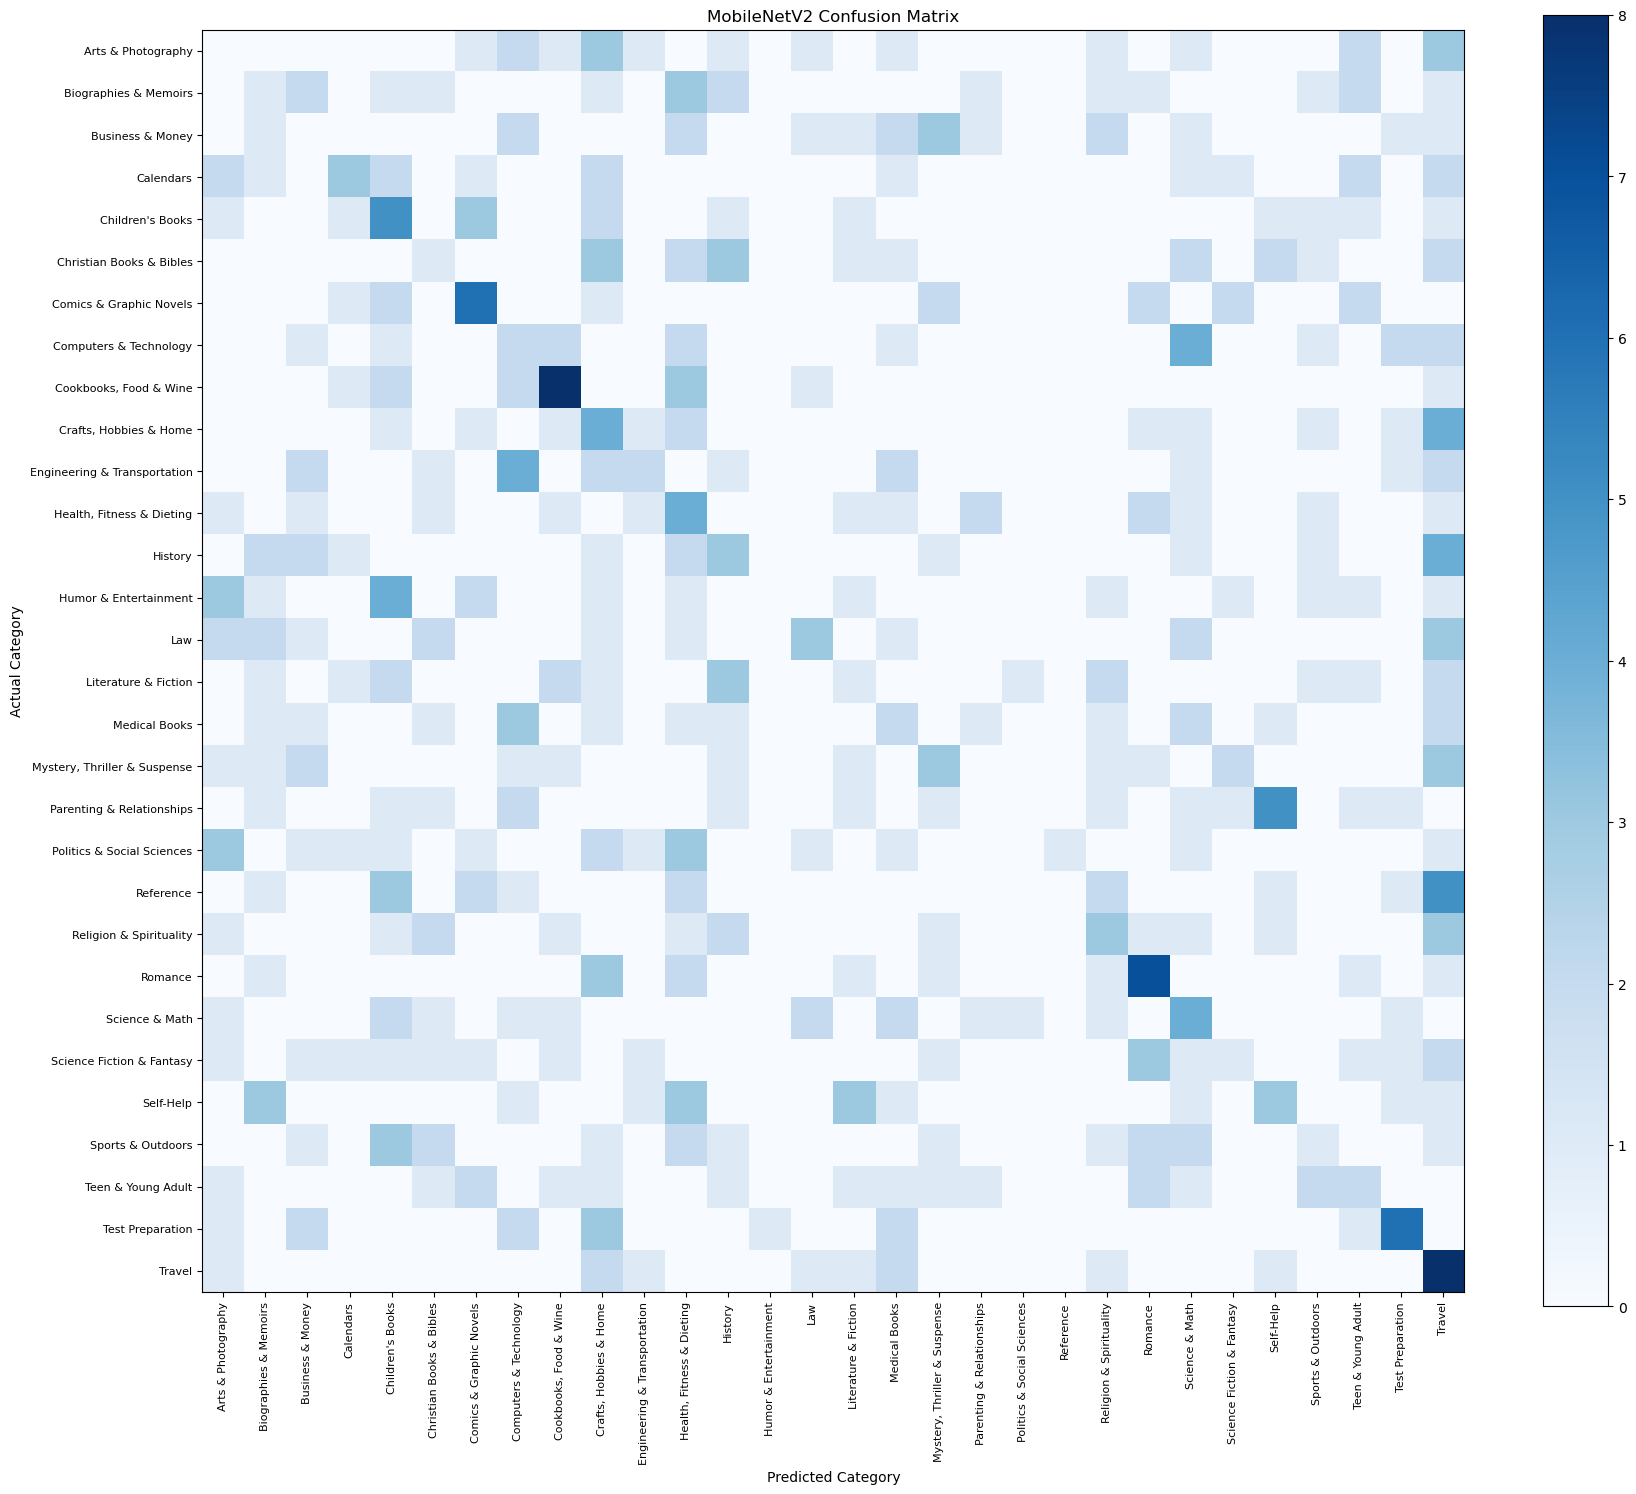

In [55]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(18, 15))

plt.imshow(mobilenet_cm, interpolation="nearest", cmap="Blues")

plt.title("MobileNetV2 Confusion Matrix")
plt.colorbar()

categories = label_encoder.classes_

plt.xticks(
    np.arange(30),
    categories,
    rotation=90,
    fontsize=8
)

plt.yticks(
    np.arange(30),
    categories,
    fontsize=8
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

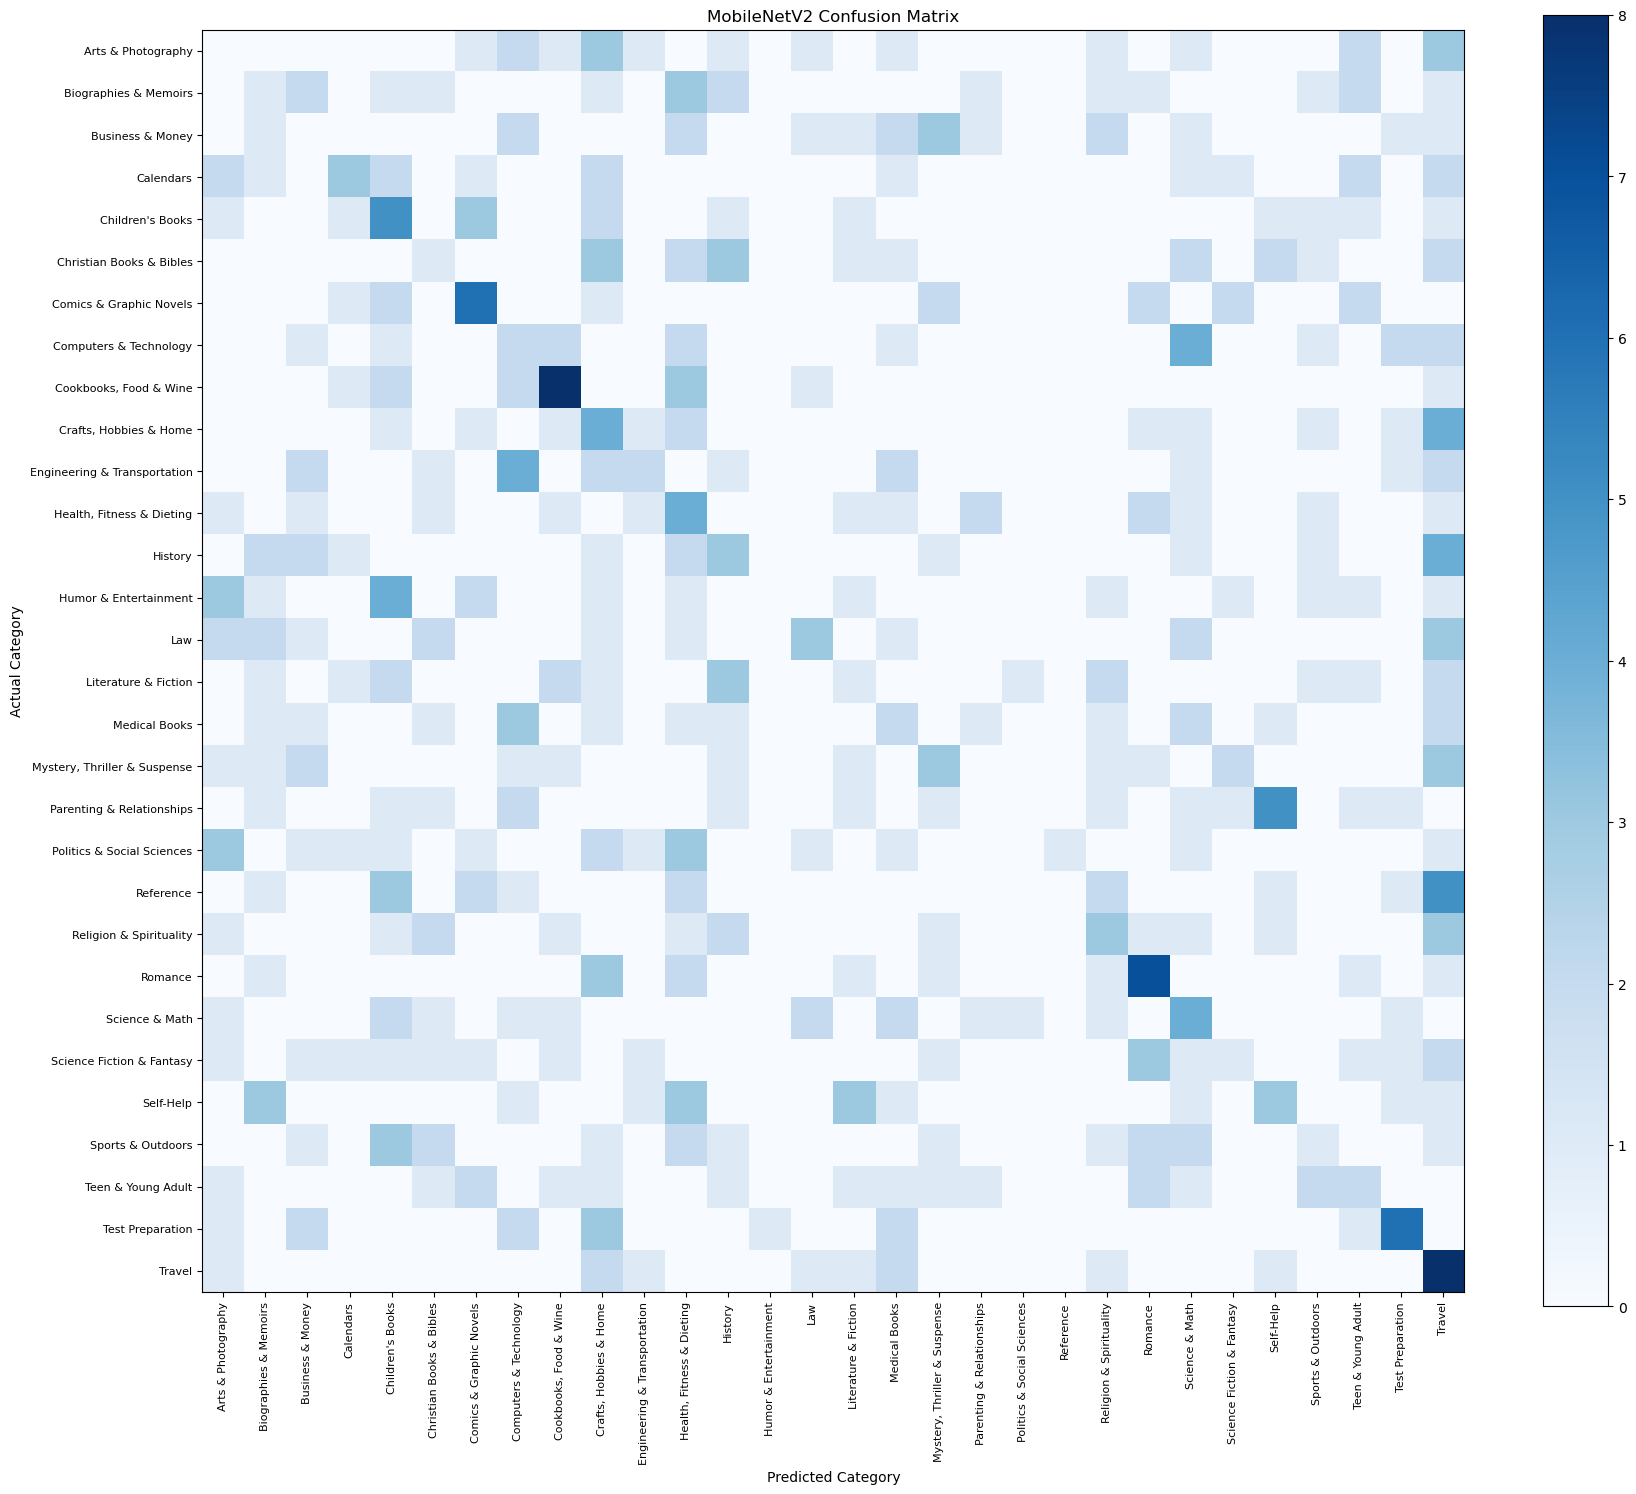

In [56]:
plt.figure(figsize=(18, 15))

plt.imshow(mobilenet_cm, interpolation="nearest", cmap="Blues")
plt.title("MobileNetV2 Confusion Matrix")
plt.colorbar()

categories = label_encoder.classes_

plt.xticks(np.arange(30), categories, rotation=90, fontsize=8)
plt.yticks(np.arange(30), categories, fontsize=8)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()

plt.savefig(
    "mobilenetv2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [57]:
import os

print(os.path.abspath("mobilenetv2_confusion_matrix.png"))
print(os.path.exists("mobilenetv2_confusion_matrix.png"))

C:\Users\mosim\mobilenetv2_confusion_matrix.png
True


In [58]:
# Save the final fine-tuned MobileNetV2 model

mobilenet_model.save("book30_mobilenetv2_final.keras")

print("Final MobileNetV2 model saved successfully!")

Final MobileNetV2 model saved successfully!


In [59]:
import os

model_path = os.path.abspath("book30_mobilenetv2_final.keras")

print("Model location:", model_path)
print("Model saved:", os.path.exists(model_path))

Model location: C:\Users\mosim\book30_mobilenetv2_final.keras
Model saved: True


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


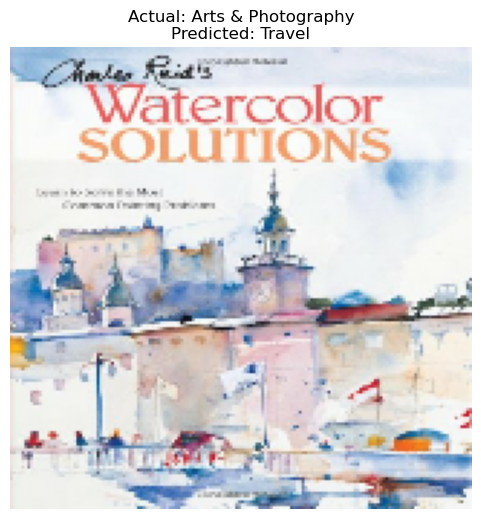

Actual category: Arts & Photography
Predicted category: Travel
Prediction confidence: 27.65 %


In [60]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

# Select one test image
sample_image_path = X_test_paths[0]

# Load and prepare the image
image = tf.io.read_file(sample_image_path)
image = tf.image.decode_image(
    image,
    channels=3,
    expand_animations=False
)

image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

# Prepare image for MobileNetV2
image_array = preprocess_input(image.numpy())
image_array = np.expand_dims(image_array, axis=0)

# Make prediction
prediction = mobilenet_model.predict(image_array)

predicted_label = np.argmax(prediction[0])
predicted_category = label_encoder.inverse_transform(
    [predicted_label]
)[0]

# Get actual category
actual_label = y_test_full[0]
actual_category = label_encoder.inverse_transform(
    [actual_label]
)[0]

# Display results
plt.figure(figsize=(6, 6))
plt.imshow(tf.cast(image, tf.uint8))
plt.axis("off")
plt.title(
    f"Actual: {actual_category}\nPredicted: {predicted_category}"
)
plt.show()

print("Actual category:", actual_category)
print("Predicted category:", predicted_category)
print("Prediction confidence:", round(float(np.max(prediction)) * 100, 2), "%")

In [61]:
# Select five test images
sample_indices = range(5)

for index in sample_indices:

    image_path = X_test_paths[index]

    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    image_array = preprocess_input(image.numpy())
    image_array = np.expand_dims(image_array, axis=0)

    prediction = mobilenet_model.predict(
        image_array,
        verbose=0
    )

    predicted_label = np.argmax(prediction[0])

    predicted_category = label_encoder.inverse_transform(
        [predicted_label]
    )[0]

    actual_category = label_encoder.inverse_transform(
        [y_test_full[index]]
    )[0]

    confidence = np.max(prediction[0]) * 100

    print("Image:", index + 1)
    print("Actual category:", actual_category)
    print("Predicted category:", predicted_category)
    print("Confidence:", round(confidence, 2), "%")
    print("Correct:", actual_category == predicted_category)
    print("-" * 45)

Image: 1
Actual category: Arts & Photography
Predicted category: Travel
Confidence: 27.65 %
Correct: False
---------------------------------------------
Image: 2
Actual category: Arts & Photography
Predicted category: Teen & Young Adult
Confidence: 24.83 %
Correct: False
---------------------------------------------
Image: 3
Actual category: Arts & Photography
Predicted category: Computers & Technology
Confidence: 16.3 %
Correct: False
---------------------------------------------
Image: 4
Actual category: Arts & Photography
Predicted category: Travel
Confidence: 17.83 %
Correct: False
---------------------------------------------
Image: 5
Actual category: Arts & Photography
Predicted category: Teen & Young Adult
Confidence: 9.82 %
Correct: False
---------------------------------------------


In [62]:
# Select five random test images from different positions
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X_test_paths),
    size=5,
    replace=False
)

correct_predictions = 0

for index in sample_indices:

    image_path = X_test_paths[index]

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    image_array = preprocess_input(image.numpy())
    image_array = np.expand_dims(image_array, axis=0)

    prediction = mobilenet_model.predict(
        image_array,
        verbose=0
    )

    predicted_label = np.argmax(prediction[0])

    predicted_category = label_encoder.inverse_transform(
        [predicted_label]
    )[0]

    actual_category = label_encoder.inverse_transform(
        [y_test_full[index]]
    )[0]

    confidence = np.max(prediction[0]) * 100

    is_correct = actual_category == predicted_category

    if is_correct:
        correct_predictions += 1

    print("Actual category:", actual_category)
    print("Predicted category:", predicted_category)
    print("Confidence:", round(confidence, 2), "%")
    print("Correct:", is_correct)
    print("-" * 45)

print("Correct predictions:", correct_predictions, "out of 5")

Actual category: Science & Math
Predicted category: Law
Confidence: 14.8 %
Correct: False
---------------------------------------------
Actual category: Humor & Entertainment
Predicted category: Children's Books
Confidence: 57.23 %
Correct: False
---------------------------------------------
Actual category: Politics & Social Sciences
Predicted category: Business & Money
Confidence: 29.01 %
Correct: False
---------------------------------------------
Actual category: Business & Money
Predicted category: Literature & Fiction
Confidence: 34.7 %
Correct: False
---------------------------------------------
Actual category: History
Predicted category: Travel
Confidence: 22.23 %
Correct: False
---------------------------------------------
Correct predictions: 0 out of 5


In [63]:
print("TRAINING DATA SUMMARY")
print("Original training records:", len(train_df))
print("Available training images:", len(train_available_df))

print("\nTESTING DATA SUMMARY")
print("Original testing records:", len(test_df))
print("Available testing images:", len(test_available_df))

print("\nCATEGORY DISTRIBUTION - AVAILABLE TRAINING IMAGES")
print(train_available_df["category"].value_counts().sort_index())

print("\nMISSING VALUES - TRAINING DATA")
print(train_df.isnull().sum())

print("\nMISSING VALUES - TEST DATA")
print(test_df.isnull().sum())

print("\nIMAGE DATA SUMMARY")
print("Training images used:", len(X_train_paths))
print("Validation images used:", len(X_val_paths))
print("Test images used:", len(X_test_paths))

TRAINING DATA SUMMARY
Original training records: 51300
Available training images: 5009

TESTING DATA SUMMARY
Original testing records: 5700
Available testing images: 2010

CATEGORY DISTRIBUTION - AVAILABLE TRAINING IMAGES
category
Arts & Photography              170
Biographies & Memoirs           148
Business & Money                193
Calendars                       126
Children's Books                234
Christian Books & Bibles        182
Comics & Graphic Novels         136
Computers & Technology          176
Cookbooks, Food & Wine          200
Crafts, Hobbies & Home          209
Engineering & Transportation    120
Health, Fitness & Dieting       216
History                         167
Humor & Entertainment           152
Law                             154
Literature & Fiction            170
Medical Books                   223
Mystery, Thriller & Suspense    119
Parenting & Relationships       133
Politics & Social Sciences      132
Reference                       124
Religion & Sp

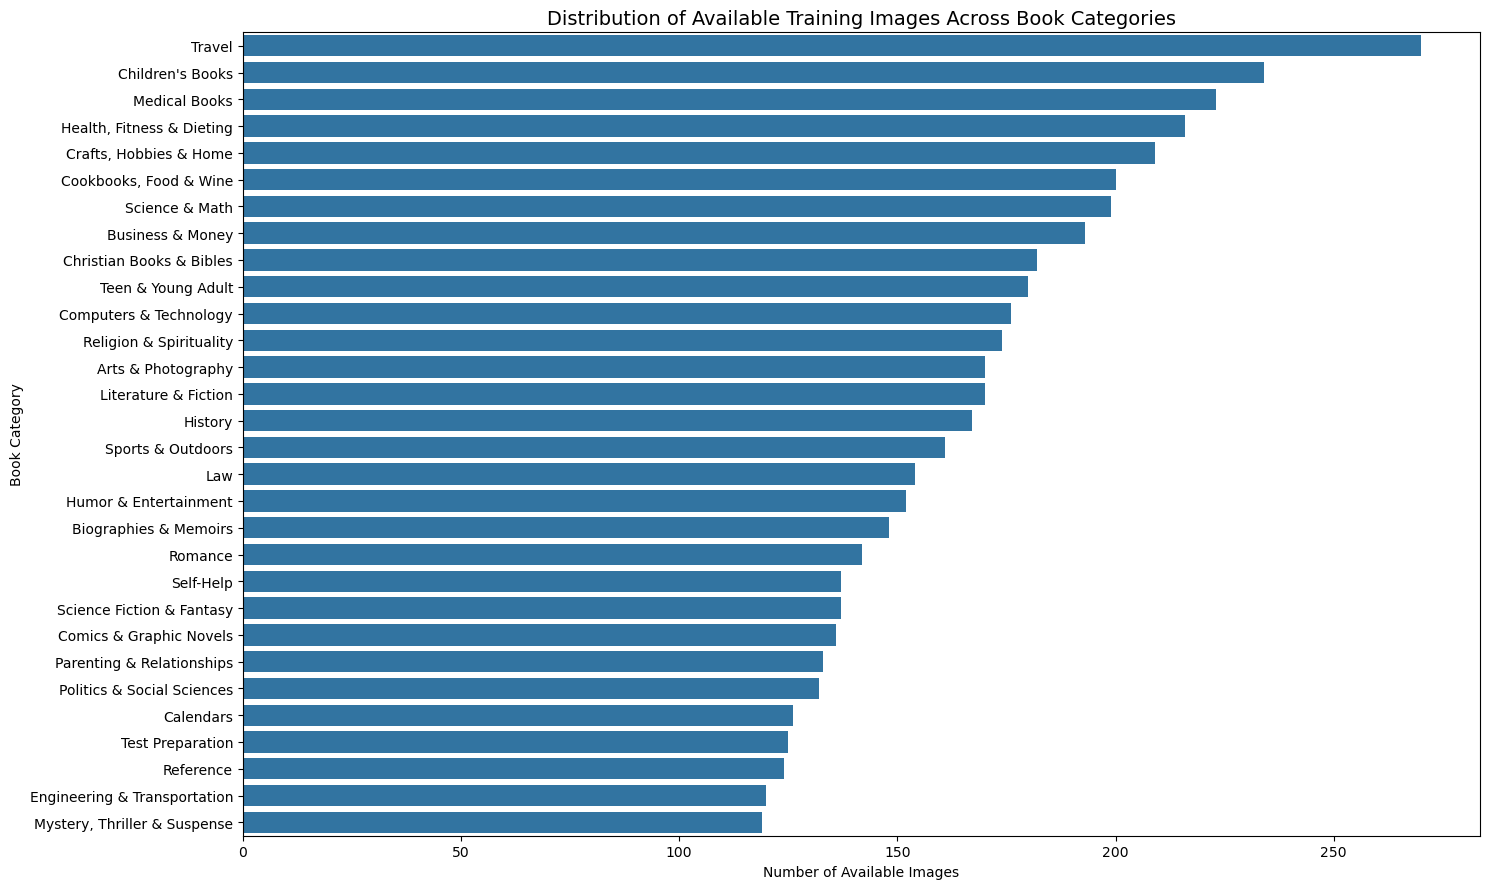

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the number of available images in each category
category_counts = (
    train_available_df["category"]
    .value_counts()
    .sort_values(ascending=False)
)

# Create a bar chart
plt.figure(figsize=(15, 9))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title(
    "Distribution of Available Training Images Across Book Categories",
    fontsize=14
)

plt.xlabel("Number of Available Images")
plt.ylabel("Book Category")

plt.tight_layout()

# Save the graph for the report
plt.savefig(
    "book30_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()